# Projeto AM 2026-2 — o pipeline completo, comentado

Este notebook refaz o projeto de ponta a ponta. Para cada item ele mostra **o que o enunciado pede**, **o que foi
feito** e **como foi feito**, com o código ao lado da explicação.

**Sobre o código.** Este notebook reúne todo o código do projeto, em Python, sem depender de outros scripts. A
Questão 1 também tem uma implementação em R (`double-kmeans-spambase/double_kmeans_spambase.R`), com o mesmo
algoritmo, e o notebook compara os dois resultados. Em vários pontos ele **confere** os próprios resultados com as
saídas salvas no repositório (`output/`), que são as apresentadas no relatório e nos slides.

**Como executar.** Localmente, a partir da pasta do repositório. No Google Colab, o notebook baixa o repositório
(público) na primeira execução.

**Como as duas questões se ligam:**

```
spambase.data ──► Q1: double k-means para cada (K, H) ──► K* pela silhueta ──► cl_star (cluster de cada e-mail)
      │                                                                              │
      ├──► Q2, versão 1: resposta = spam / não-spam                                  │
      └──► Q2, versão 2: resposta = cl_star ◄────────────────────────────────────────┘
                 │
                 └──► 5 classificadores, CV 30 × 10 aninhada ──► (b) IC  (c) Friedman/Nemenyi  (d) curvas
```

**Roteiro**

1. Os dados
2. Questão 1 — double k-means
3. Questão 2 — classificadores: protocolo, classificadores, itens (a), (b), (c) e (d)
4. Arquivos do repositório

**Tempo de execução.** Com as opções abaixo, cerca de 5 minutos. A Questão 1 roda inteira ao vivo. No item (a), um
split é feito passo a passo ao vivo e os 600 splits completos são lidos de `questao-02/output/`, a não ser que
`RODAR_CV_COMPLETA = True`.

In [1]:
# ==== Opções de execução ====
RODAR_CV_COMPLETA = False   # True: refaz os 2 × 300 splits do item (a) (~30 min com 4 processos); False: lê questao-02/output/
RODAR_CURVAS = True         # True: refaz as curvas do item (d) (~2 min); False: lê questao-02/output/
N_JOBS = 4                  # processos em paralelo (-1 = todos os núcleos)

In [2]:
import json
import subprocess
import sys
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy import stats
from scipy.linalg import cho_factor, cho_solve
from scipy.spatial.distance import cdist
from scipy.special import logsumexp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, adjusted_rand_score, confusion_matrix, f1_score,
                             precision_score, recall_score, silhouette_score)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler

# No Colab, baixa o repositório na primeira execução.
if "google.colab" in sys.modules and not Path("IN1102-AM").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/ergdln/IN1102-AM.git"], check=True)

candidatas = [Path.cwd(), Path.cwd().parent, Path("IN1102-AM")]
RAIZ = next(p.resolve() for p in candidatas if (p / "double-kmeans-spambase").exists())
ARQ_DADOS = RAIZ / "double-kmeans-spambase" / "data" / "spambase.data"
Q1_OUT = RAIZ / "double-kmeans-spambase" / "output"   # saídas oficiais da Questão 1 (script R)
Q2_OUT = RAIZ / "questao-02" / "output"               # saídas oficiais da Questão 2 (scripts Python)
Q2_SPLITS = RAIZ / "questao-02" / "splits"

SEMENTE = 2026
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", None)   # não corta as colunas de texto das tabelas
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Raiz do repositório:", RAIZ.name)

Raiz do repositório: IN1102-AM


---
## 1. Os dados

O enunciado pede, no relatório, "uma descrição sucinta dos dados".

A **Spambase** (UCI) tem 4601 e-mails, cada um descrito por 57 atributos numéricos e rotulado como spam (1) ou
não-spam (0). Os atributos são de três tipos:

- **48 frequências de palavras** (`word_freq_*`): porcentagem das palavras do e-mail iguais a uma palavra-alvo
  ("free", "money", "hp", "george"...);
- **6 frequências de caracteres** (`char_freq_*`): porcentagem de `;`, `(`, `[`, `!`, `$` e `#`;
- **3 estatísticas de sequências de MAIÚSCULAS**: comprimento médio, maior comprimento e total de letras maiúsculas
  em sequência.

In [3]:
NOMES_VARS = [
    "word_freq_make", "word_freq_address", "word_freq_all", "word_freq_3d", "word_freq_our",
    "word_freq_over", "word_freq_remove", "word_freq_internet", "word_freq_order", "word_freq_mail",
    "word_freq_receive", "word_freq_will", "word_freq_people", "word_freq_report", "word_freq_addresses",
    "word_freq_free", "word_freq_business", "word_freq_email", "word_freq_you", "word_freq_credit",
    "word_freq_your", "word_freq_font", "word_freq_000", "word_freq_money", "word_freq_hp",
    "word_freq_hpl", "word_freq_george", "word_freq_650", "word_freq_lab", "word_freq_labs",
    "word_freq_telnet", "word_freq_857", "word_freq_data", "word_freq_415", "word_freq_85",
    "word_freq_technology", "word_freq_1999", "word_freq_parts", "word_freq_pm", "word_freq_direct",
    "word_freq_cs", "word_freq_meeting", "word_freq_original", "word_freq_project", "word_freq_re",
    "word_freq_edu", "word_freq_table", "word_freq_conference", "char_freq_semicolon", "char_freq_paren",
    "char_freq_bracket", "char_freq_bang", "char_freq_dollar", "char_freq_hash",
    "capital_run_length_average", "capital_run_length_longest", "capital_run_length_total",
]

dados = pd.read_csv(ARQ_DADOS, header=None)
X = dados.iloc[:, :57].to_numpy(float)       # 4601 x 57
y_spam = dados.iloc[:, 57].to_numpy(int)     # 1 = spam, 0 = não-spam
df = pd.DataFrame(X, columns=NOMES_VARS)
n, J = X.shape

print(f"{n} e-mails × {J} atributos, sem valores ausentes: {not df.isna().any().any()}")
print(f"spam: {y_spam.sum()} ({y_spam.mean():.1%})  |  não-spam: {n - y_spam.sum()} ({1 - y_spam.mean():.1%})")
rotulos_por_x = dados.groupby(list(range(57)))[57].nunique()
print(f"linhas com atributos repetidos: {df.duplicated().sum()} cópias "
      f"({(rotulos_por_x > 1).sum()} grupos de cópias têm rótulos diferentes)")

grupos = {"48 frequências de palavras (%)": NOMES_VARS[:48],
          "6 frequências de caracteres (%)": NOMES_VARS[48:54],
          "3 sequências de maiúsculas": NOMES_VARS[54:]}
resumo_dados = pd.DataFrame([{
    "grupo": g,
    "mínimo": df[cols].min().min(),
    "máximo": df[cols].max().max(),
    "% de zeros (mediana entre as variáveis)": 100 * (df[cols] == 0).mean().median(),
    "assimetria (mediana entre as variáveis)": df[cols].skew().median(),
} for g, cols in grupos.items()]).set_index("grupo")
display(resumo_dados.round(1))

4601 e-mails × 57 atributos, sem valores ausentes: True
spam: 1813 (39.4%)  |  não-spam: 2788 (60.6%)
linhas com atributos repetidos: 394 cópias (3 grupos de cópias têm rótulos diferentes)


,mínimo,máximo,% de zeros (mediana entre as variáveis),assimetria (mediana entre as variáveis)
grupo,,,,
48 frequências de palavras (%),0.0,42.8,86.1,8.8
6 frequências de caracteres (%),0.0,32.5,76.2,16.2
3 sequências de maiúsculas,1.0,15841.0,0.0,23.8


**O que isso implica para o resto do projeto:**

- **Escalas muito diferentes.** As frequências vão de 0 a ~43, mas `capital_run_length_total` chega a 15841. Qualquer
  método baseado em distância (double k-means, k-vizinhos, Parzen) seria dominado por esse atributo. Por isso os dados
  são **padronizados (z-score)** em todas as etapas.
- **Muitos zeros e forte assimetria.** A palavra típica não aparece em ~86% dos e-mails, e as distribuições têm
  caudas longas (assimetria mediana ~9). Os dados estão longe de uma normal. Isso vai pesar contra o classificador
  gaussiano (Q2) e faz com que poucos e-mails extremos dominem a soma de quadrados do double k-means (Q1).
- **Linhas repetidas.** 394 e-mails repetem os atributos de outro. Isso gera empates de distância no k-vizinhos,
  tratados explicitamente na Seção 3.

---
## 2. Questão 1 — double k-means

### 2.1 O que o enunciado pede

> Execute o algoritmo double k-means 100 vezes com K ∈ {2, 3, 4} e, para cada K, com H ∈ {1, …, K}. Para cada par
> (K, H), selecione o melhor resultado segundo a função objetivo. Para cada par, calcule a silhueta (Sil), faça o
> plot Sil × (K, H) e escolha o número de clusters de objetos K\* = arg max Sil(K, H). Para a partição de objetos
> com K\*, calcule o índice de Rand corrigido e comente. Para o melhor resultado com K\*, mostre: i) a matriz de
> protótipos dos blocos G; ii) a matriz de confusão da partição do algoritmo versus a partição a priori; iv) o plot
> da função objetivo versus as iterações.

### 2.2 A ideia do double k-means (Vichi, 2001)

O k-means comum agrupa só as **linhas** (os e-mails). O double k-means agrupa **ao mesmo tempo** as linhas, em K
clusters de objetos, e as **colunas**, em H clusters de variáveis. O cruzamento de um cluster de objetos com um
cluster de variáveis forma um **bloco**, resumido por um único número: a média do bloco.

Notação:

| Matriz | Tamanho | Significado |
|---|---|---|
| $X$ | $n \times J$ | dados padronizados |
| $U$ | $n \times K$ | $U_{ik} = 1$ se o objeto $i$ está no cluster $k$ |
| $V$ | $J \times H$ | $V_{jh} = 1$ se a variável $j$ está no cluster $h$ |
| $G$ | $K \times H$ | protótipos: $G_{kh}$ = média de $X$ no bloco $(k, h)$ |

**Modelo.** $X \approx B = U\,G\,V^\top$: o valor previsto para $x_{ij}$ é o protótipo $G_{kh}$ do bloco do objeto
$i$ e da variável $j$.

**Função objetivo.** O algoritmo minimiza o erro quadrático $\lVert X - UGV^\top \rVert^2$. Como $G$ é sempre a média
dos blocos, vale $\lVert X \rVert^2 = \lVert B \rVert^2 + \lVert X - B \rVert^2$. Como $\lVert X \rVert^2$ é
constante, minimizar o erro é o mesmo que **maximizar** $f = \lVert B \rVert^2 = \mathrm{tr}(B^\top B)$. O projeto
reporta $f$, em que **maior é melhor**; $f / \lVert X \rVert^2$ é a fração da variância explicada pelos blocos.

**Algoritmo (mínimos quadrados alternados).** Parte de $U$ e $V$ aleatórios e repete até $f$ parar de crescer:

1. fixados $V$ e $G$, cada **objeto** vai para o cluster cujo perfil (linha de $GV^\top$) está mais perto dele;
   recalcula $G$;
2. fixados $U$ e $G$, cada **variável** vai para o cluster cujo perfil (coluna de $UG$) está mais perto dela;
   recalcula $G$.

Nenhum passo piora $f$, então o algoritmo converge, mas só para um **ótimo local**. Por isso cada par $(K, H)$ é
rodado 100 vezes, com inicializações diferentes, e fica a execução de maior $f$.

### 2.3 Pré-processamento

Z-score em cada variável, como o `scale()` do R (desvio-padrão com $n-1$). Depois dele, toda variável tem variância
1 e $\lVert X \rVert^2 = (n-1)J$.

Na Questão 1 a padronização usa a base inteira. Isso é correto aqui: clustering não tem conjunto de teste, e o
rótulo spam/não-spam nunca entra no algoritmo; ele só é usado depois, para avaliar (ARI e matriz de confusão).

In [4]:
Xs = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
SQ_TOTAL = (Xs ** 2).sum()
print(f"||X||² = {SQ_TOTAL:.0f}  (= (n-1)·J = {(n - 1) * J})")

||X||² = 262200  (= (n-1)·J = 262200)


### 2.4 Implementação

É a mesma do script R (seção 2), traduzida para numpy. Dois detalhes:

- **Atualização eficiente.** A distância de $x_i$ ao perfil do cluster $k$ é
  $\lVert x_i \rVert^2 - 2\,x_i \cdot \text{perfil}_k + \lVert \text{perfil}_k \rVert^2$. O primeiro termo não muda
  com $k$, então só os dois últimos importam. Eles saem de produtos de matrizes pequenas: $XV$ ($n \times H$) para
  os objetos e $X^\top U$ ($J \times K$) para as variáveis.
- **Cluster vazio.** Se um cluster perde todos os elementos, ele recebe o elemento pior ajustado de um cluster com
  mais de um elemento. Sem isso, o algoritmo terminaria com menos de K (ou H) clusters.

In [5]:
def particao_aleatoria(rng, m, k):
    # Sorteia um rótulo 0..k-1 para cada um dos m elementos, até nenhum cluster ficar vazio.
    while True:
        rotulo = rng.integers(0, k, m)
        if len(np.unique(rotulo)) == k:
            return rotulo


def indicadora(rotulo, k):
    # Vetor de rótulos -> matriz indicadora (m x k).
    M = np.zeros((len(rotulo), k))
    M[np.arange(len(rotulo)), rotulo] = 1
    return M


def calcula_G(X, U, V):
    # G = (U'U)^-1 U'XV (V'V)^-1: soma de cada bloco dividida pelo número de células do bloco.
    return (U.T @ X @ V) / np.outer(U.sum(0), V.sum(0))


def funcao_objetivo(G, U, V):
    # f = ||U G V'||² = soma_{k,h} n_k · p_h · G[k,h]²  (sem montar a matriz B, que é n x J)
    return float(np.sum(np.outer(U.sum(0), V.sum(0)) * G ** 2))


def atualiza_particao(P, G, tamanhos_outro, xx):
    # Passo de U (P = XV, G) ou de V (P = X'U, G').
    # D[i,k] = ||x_i - perfil_k||² sem o termo ||x_i||², que não muda o arg min.
    k = G.shape[0]
    D = -2 * P @ G.T + (G ** 2) @ tamanhos_outro
    rotulo = np.argmin(D, axis=1)
    for vazio in sorted(set(range(k)) - set(rotulo)):           # tratamento de cluster vazio
        dist_propria = D[np.arange(len(rotulo)), rotulo] + xx
        doador_ok = np.bincount(rotulo, minlength=k)[rotulo] > 1
        dist_propria[~doador_ok] = -np.inf
        rotulo[np.argmax(dist_propria)] = vazio
    return rotulo


def dkm_uma_execucao(rng, X, K, H, maxiter=200, tol=1e-6):
    xx_linhas, xx_colunas = (X ** 2).sum(1), (X ** 2).sum(0)
    U = indicadora(particao_aleatoria(rng, X.shape[0], K), K)
    V = indicadora(particao_aleatoria(rng, X.shape[1], H), H)
    G = calcula_G(X, U, V)
    f_iter = [funcao_objetivo(G, U, V)]                          # "iteração 0": após a inicialização
    for _ in range(maxiter):
        U = indicadora(atualiza_particao(X @ V, G, V.sum(0), xx_linhas), K)      # (1) objetos
        G = calcula_G(X, U, V)
        V = indicadora(atualiza_particao(X.T @ U, G.T, U.sum(0), xx_colunas), H)  # (2) variáveis
        G = calcula_G(X, U, V)
        f_iter.append(funcao_objetivo(G, U, V))
        if f_iter[-1] - f_iter[-2] <= tol:                       # parou de melhorar
            break
    return {"U": U, "V": V, "G": G, "f": f_iter[-1], "f_iter": np.array(f_iter)}


def dkm_melhor_de_n(X, K, H, n_execucoes=100, semente=SEMENTE):
    # 100 inicializações aleatórias; fica a de MAIOR f.
    rng = np.random.default_rng(semente)
    execucoes = [dkm_uma_execucao(rng, X, K, H) for _ in range(n_execucoes)]
    melhor = max(execucoes, key=lambda r: r["f"])
    melhor["f_todas"] = np.array([r["f"] for r in execucoes])
    return melhor

### 2.5 A grade (K, H): 100 execuções por par e silhueta

São 2 + 3 + 4 = 9 pares. Para cada um: 100 execuções, a melhor segundo $f$ e a silhueta média da partição de
objetos dessa melhor execução.

**Silhueta.** Para cada objeto $i$, $s(i) = \dfrac{b(i) - a(i)}{\max(a(i), b(i))}$, em que $a(i)$ é a distância média
de $i$ aos outros objetos do seu cluster e $b(i)$ é a menor distância média de $i$ aos objetos de outro cluster.
$s(i)$ perto de 1 indica objeto bem agrupado; perto de 0, objeto na fronteira; negativo, objeto provavelmente no
cluster errado. Sil é a média de $s(i)$. Ela é calculada com a distância euclidiana nas 57 variáveis padronizadas,
o mesmo espaço em que o algoritmo trabalha.

In [6]:
grade = [(K, H) for K in (2, 3, 4) for H in range(1, K + 1)]
melhores = {}
linhas = []
for K, H in grade:
    res = dkm_melhor_de_n(Xs, K, H)
    melhores[(K, H)] = res
    linhas.append({"K": K, "H": H, "f": res["f"], "% var. explicada": 100 * res["f"] / SQ_TOTAL,
                   "execuções no melhor f": int(np.sum(res["f_todas"] > res["f"] - 1e-6 * res["f"])),
                   "Sil": silhouette_score(Xs, res["U"].argmax(1))})
resumo_q1 = pd.DataFrame(linhas)

# Comparação com as saídas oficiais do script R
ref_r = pd.read_csv(Q1_OUT / "resultados_KH.csv")
comparacao = resumo_q1.merge(ref_r[["K", "H", "f", "f_drclust", "Sil"]], on=["K", "H"], suffixes=(" (Python)", " (R)"))
display(comparacao.round(4))

,K,H,f (Python),% var. explicada,execuções no melhor f,Sil (Python),f (R),f_drclust,Sil (R)
0,2,1,5742.0035,2.1899,100,0.2961,5742.0035,5742.0035,0.2961
1,2,2,17766.4394,6.7759,5,0.6596,17766.4394,17766.4394,0.6596
2,3,1,7841.2825,2.9906,100,0.2515,7841.2825,7841.2825,0.2515
3,3,2,22878.3688,8.7255,4,0.2454,22878.3688,22830.2515,0.2454
4,3,3,27817.1535,10.6091,12,0.1426,27817.1704,27817.1535,0.1419
5,4,1,8976.3691,3.4235,100,0.0484,8976.3691,8976.3691,0.0484
6,4,2,28892.0169,11.0191,63,0.2428,28899.4222,28892.0169,0.2444
7,4,3,33733.2230,12.8655,25,0.1620,33733.2230,33733.2230,0.1620
8,4,4,35211.1555,13.4291,1,0.1609,35069.2532,35163.2781,0.1642


**Como ler a tabela.** As colunas "(R)" são a tabela do relatório, gerada pelo script R. A coluna `f_drclust` é o
mesmo cálculo feito pelo pacote `drclust`, usado como conferência da implementação. Python e R sorteiam as 100
inicializações com geradores diferentes. Nos pares em que o melhor f aparece com frequência, os dois chegam ao mesmo
f e à mesma silhueta. Nos pares em que ele é raro ((3,3), (4,2) e (4,4)), cada um pode parar num ótimo local um
pouco diferente. O par escolhido, **(2,2)**, é o mesmo nas duas linguagens, com o mesmo f, a mesma silhueta e (como
conferido na Seção 2.8) a mesma partição.

### 2.6 Plot Sil × (K, H) e escolha de K\*

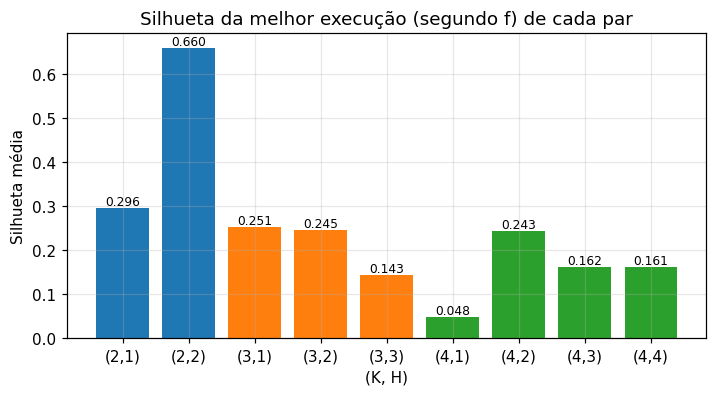

(K*, H*) = (2, 2), Sil = 0.6596


In [7]:
rotulos_kh = [f"({K},{H})" for K, H in grade]
cores = {2: "tab:blue", 3: "tab:orange", 4: "tab:green"}
fig, eixo = plt.subplots(figsize=(7.5, 3.6))
barras = eixo.bar(rotulos_kh, resumo_q1["Sil"], color=[cores[K] for K, _ in grade])
eixo.bar_label(barras, fmt="%.3f", fontsize=8)
eixo.set_xlabel("(K, H)")
eixo.set_ylabel("Silhueta média")
eixo.set_title("Silhueta da melhor execução (segundo f) de cada par")
plt.show()

i_star = int(resumo_q1["Sil"].idxmax())
K_STAR, H_STAR = grade[i_star]
melhor = melhores[(K_STAR, H_STAR)]
print(f"(K*, H*) = ({K_STAR}, {H_STAR}), Sil = {resumo_q1['Sil'][i_star]:.4f}")

O par (2,2) vence com folga (Sil ≈ 0,66; nenhum outro passa de 0,30). Como a silhueta é calculada por par, o máximo
indica também o H\* correspondente. **K\* = 2**, então a versão 2 da Questão 2 terá 2 classes.

### 2.7 Índice de Rand corrigido (ARI)

O índice de Rand é a fração de **pares de objetos** em que duas partições concordam (os dois juntos nas duas, ou
separados nas duas). Ele é alto até para partições aleatórias. O ARI (Hubert & Arabie, 1985) desconta o valor
esperado ao acaso:

$$\text{ARI} = \frac{\text{Índice} - \text{Esperado}}{\text{Máximo} - \text{Esperado}}, \qquad
\text{Índice} = \sum_{ij}\binom{n_{ij}}{2},\quad
\text{Esperado} = \frac{\sum_i \binom{a_i}{2}\sum_j \binom{b_j}{2}}{\binom{n}{2}},\quad
\text{Máximo} = \tfrac12\Big[\sum_i \binom{a_i}{2} + \sum_j \binom{b_j}{2}\Big]$$

em que $n_{ij}$ é a tabela de contingência (cluster × classe) e $a_i$, $b_j$ são os totais das linhas e das colunas.
ARI = 1 indica partições idênticas; ARI ≈ 0, concordância de acaso; ARI < 0, concordância pior que o acaso.

In [8]:
def ari(particao_a, particao_b):
    N = pd.crosstab(particao_a, particao_b).to_numpy()
    c2 = lambda x: x * (x - 1) / 2                     # "x escolhe 2"
    indice = c2(N).sum()
    soma_linhas, soma_colunas = c2(N.sum(1)).sum(), c2(N.sum(0)).sum()
    esperado = soma_linhas * soma_colunas / c2(N.sum())
    maximo = (soma_linhas + soma_colunas) / 2
    return (indice - esperado) / (maximo - esperado)


cl_python = melhor["U"].argmax(1)
print(f"ARI (implementação acima)  = {ari(cl_python, y_spam):.4f}")
print(f"ARI (sklearn, conferência) = {adjusted_rand_score(y_spam, cl_python):.4f}")
print(f"ARI oficial (script R)     : {(Q1_OUT / 'ari.txt').read_text().strip()}")

ARI (implementação acima)  = -0.0049
ARI (sklearn, conferência) = -0.0049
ARI oficial (script R)     : K*=2 H*=2 ARI=-0.004950


**Comentário.** O ARI é praticamente zero (levemente negativo): a partição do double k-means **não tem relação** com
spam / não-spam. O motivo aparece na matriz de confusão logo abaixo. Um dos clusters isola 34 e-mails com valores
extremos (outliers); o outro, com 4567 e-mails, tem praticamente a mesma proporção de spam da base inteira.

Isso não é um "erro" do algoritmo. O double k-means minimiza uma soma de quadrados nos dados padronizados e não
enxerga o rótulo. Em dados com caudas longas, poucos pontos extremos pesam muito nessa soma. A silhueta também
favorece essa solução, porque um grupo pequeno e muito afastado é "bem separado" geometricamente.

### 2.8 Resultados do melhor modelo com K\*

Antes de mostrar os resultados, os clusters do Python são renumerados para coincidir com os do R. A numeração dos
clusters é arbitrária: "cluster 1" do Python pode ser o "cluster 2" do R. Em seguida, conferimos que a partição é
idêntica à que foi usada na Questão 2 (`cl_star.csv`).

In [9]:
# Alinha a numeração dos clusters de OBJETOS com a do R (cl_star.csv) e a de VARIÁVEIS com clusters_de_variaveis.csv.
cl_star_r = pd.read_csv(Q1_OUT / "cl_star.csv")["cluster"].to_numpy() - 1
cl_vars_r = pd.read_csv(Q1_OUT / "clusters_de_variaveis.csv")["cluster_var"].to_numpy() - 1
cl_vars_py = melhor["V"].argmax(1)

perm_u = {k: np.bincount(cl_star_r[cl_python == k], minlength=K_STAR).argmax() for k in range(K_STAR)}
perm_v = {h: np.bincount(cl_vars_r[cl_vars_py == h], minlength=H_STAR).argmax() for h in range(H_STAR)}
cl_objetos = np.array([perm_u[k] for k in cl_python])
cl_variaveis = np.array([perm_v[h] for h in cl_vars_py])
ordem_u = [k for k, _ in sorted(perm_u.items(), key=lambda p: p[1])]
ordem_v = [h for h, _ in sorted(perm_v.items(), key=lambda p: p[1])]
G = melhor["G"][np.ix_(ordem_u, ordem_v)]

G_r = pd.read_csv(Q1_OUT / "G_prototipos.csv", index_col=0).to_numpy()
print("partição de objetos idêntica à do R (cl_star.csv):", np.array_equal(cl_objetos, cl_star_r))
print("partição de variáveis idêntica à do R            :", np.array_equal(cl_variaveis, cl_vars_r))
print("matriz G igual à do R                            :", np.allclose(G, G_r, atol=1e-3))

partição de objetos idêntica à do R (cl_star.csv): True
partição de variáveis idêntica à do R            : True
matriz G igual à do R                            : True


#### i) Matriz de protótipos dos blocos G

Cada célula é a média (em desvios-padrão, porque os dados estão em z-score) das variáveis do cluster de variáveis $h$
entre os e-mails do cluster de objetos $k$.

In [10]:
tam_obj = np.bincount(cl_objetos)
tam_var = np.bincount(cl_variaveis)
display(pd.DataFrame(G.round(3),
                     index=[f"Objetos {k + 1} (n={tam_obj[k]})" for k in range(K_STAR)],
                     columns=[f"Variáveis {h + 1} ({tam_var[h]} vars)" for h in range(H_STAR)]))
for h in range(H_STAR):
    nomes = [v.replace("word_freq_", "") for v, c in zip(NOMES_VARS, cl_variaveis) if c == h]
    print(f"Cluster de variáveis {h + 1} ({len(nomes)}): {', '.join(nomes) if len(nomes) <= 15 else ', '.join(nomes[:15]) + ', ...'}")

,Variáveis 1 (11 vars),Variáveis 2 (46 vars)
Objetos 1 (n=34),6.860,-0.144
Objetos 2 (n=4567),-0.051,0.001


Cluster de variáveis 1 (11): hp, hpl, 650, lab, labs, telnet, 857, 415, 85, technology, direct
Cluster de variáveis 2 (46): make, address, all, 3d, our, over, remove, internet, order, mail, receive, will, people, report, addresses, ...


**Leitura.** O cluster de objetos 1 (34 e-mails) tem média **+6,9 desvios-padrão** nas 11 variáveis do cluster de
variáveis 1: hp, hpl, 650, lab, labs, telnet, 857, 415, 85, technology e direct. São palavras típicas de e-mails
internos da HP Labs, a empresa que coletou a base. O cluster 2 (4567 e-mails) fica perto de zero nos dois blocos, ou
seja, na média geral.

#### ii) Matriz de confusão: partição do algoritmo × partição a priori

In [11]:
confusao = pd.crosstab(pd.Series(cl_objetos + 1, name="cluster"),
                       pd.Series(np.where(y_spam == 1, "spam", "não-spam"), name="classe a priori"))
confusao["% spam"] = (100 * confusao["spam"] / confusao.sum(axis=1)).round(1)
display(confusao)
print(f"% de spam na base inteira: {100 * y_spam.mean():.1f}")

classe a priori,não-spam,spam,% spam
cluster,,,
1,34,0,0.0
2,2754,1813,39.7


% de spam na base inteira: 39.4


#### iv) Função objetivo × iterações

O gráfico da esquerda mostra $f = \mathrm{tr}(B^\top B)$, que o algoritmo **maximiza**. O da direita mostra a mesma
trajetória escrita como o erro $\lVert X - B \rVert^2 = \lVert X \rVert^2 - f$, que é **minimizado** (a forma em que
Vichi apresenta o problema). As duas curvas são equivalentes.

Esta é a execução vencedora no **Python**. A execução vencedora no R parte de outra inicialização aleatória, por isso
o número de iterações pode diferir. O gráfico oficial está em `double-kmeans-spambase/output/objfun_vs_iter.png`.
Como as duas chegam à mesma partição e ao mesmo f, o ponto final das curvas é o mesmo.

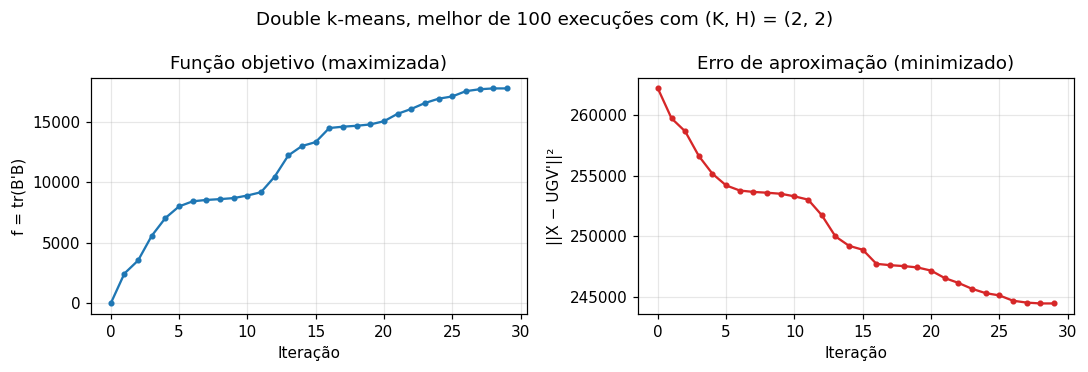

29 iterações; f final = 17766.44 (6.78% da variância)


In [12]:
f_iter = melhor["f_iter"]
assert np.all(np.diff(f_iter) >= -1e-6), "f nunca deveria diminuir"
fig, (e1, e2) = plt.subplots(1, 2, figsize=(10, 3.4))
e1.plot(f_iter, "o-", ms=3)
e1.set(xlabel="Iteração", ylabel="f = tr(B'B)", title="Função objetivo (maximizada)")
e2.plot(SQ_TOTAL - f_iter, "o-", ms=3, color="tab:red")
e2.set(xlabel="Iteração", ylabel="||X − UGV'||²", title="Erro de aproximação (minimizado)")
fig.suptitle(f"Double k-means, melhor de 100 execuções com (K, H) = ({K_STAR}, {H_STAR})")
fig.tight_layout()
plt.show()
print(f"{len(f_iter) - 1} iterações; f final = {f_iter[-1]:.2f} ({100 * f_iter[-1] / SQ_TOTAL:.2f}% da variância)")

### 2.9 Quem são os 34 e-mails, e o que isso significa para a Questão 2

Na solução final, cada e-mail está no cluster cujo perfil está mais perto dele. Para K = 2, essa regra é uma
**comparação linear**: $\lVert x - p_1\rVert^2 < \lVert x - p_2\rVert^2 \iff 2(p_1 - p_2)\cdot x >
\lVert p_1\rVert^2 - \lVert p_2\rVert^2$. Ou seja, **os rótulos da versão 2 são, por construção, um hiperplano
nos atributos**. A célula abaixo confere isso e mostra a regra em palavras.

In [13]:
perfis = G[:, cl_variaveis]                     # K x J: perfil de cada cluster de objetos
w = 2 * (perfis[0] - perfis[1])
b = (perfis[0] ** 2).sum() - (perfis[1] ** 2).sum()
regra_linear = np.where(Xs @ w > b, 0, 1)
print("a regra linear reproduz a partição em", (regra_linear == cl_objetos).sum(), "de", n, "e-mails")

media_11 = Xs[:, cl_variaveis == 0].mean(axis=1)
print(f"média z das 11 variáveis: mínimo entre os 34 = {media_11[cl_objetos == 0].min():.2f}, "
      f"máximo entre os 4567 = {media_11[cl_objetos == 1].max():.2f}")

a regra linear reproduz a partição em 4601 de 4601 e-mails
média z das 11 variáveis: mínimo entre os 34 = 3.52, máximo entre os 4567 = 3.20


Na prática, os 34 e-mails são **os que têm média z acima de ~3,3 nas 11 variáveis "HP Labs"**. Isso ajuda a ler os
resultados da versão 2 na Questão 2. A classe positiva é pequena (34 e-mails, 0,74%) e separável por um hiperplano,
então é de se esperar que os classificadores acertem quase tudo. Além disso, cada fold de teste da CV 10-fold tem só
3 ou 4 positivos, o que torna as métricas da classe positiva mais variáveis de um fold para outro.

---
## 3. Questão 2 — classificadores

### 3.1 O que o enunciado pede

> Considere 2 versões do dataset: a primeira com a variável resposta original (2 classes); a segunda com o número de
> classes igual ao número de clusters de objetos (K\*) obtido na Questão 1.
>
> **a)** Use validação cruzada estratificada "30 × 10-folds" para avaliar e comparar 5 classificadores em cada
> versão: i) bayesiano gaussiano, ii) bayesiano baseado em k-vizinhos, iii) bayesiano baseado em janela de Parzen,
> iv) regressão logística, v) voto majoritário a partir dos 4 primeiros. Quando necessário, faça validação cruzada
> 5-folds nos 9 folds restantes para ajustar os hiper-parâmetros e depois treine o modelo novamente com os 9 folds,
> usando os valores selecionados. Use amostragem estratificada.
> **b)** Obtenha uma estimativa pontual e um intervalo de confiança para cada métrica (taxa de erro, precisão,
> cobertura, F-measure).
> **c)** Use o teste de Friedman e o pós-teste de Nemenyi para comparar os classificadores, em cada métrica.
> **d)** Para a F-measure, plote a curva de aprendizagem dos 5 classificadores, com treino/teste de (5%, 95%) a
> (95%, 5%), passo de 5%, amostragem estratificada; compute as métricas no treino e no teste. Comente.

As especificações de cada classificador (MV para o gaussiano; distâncias euclidiana, city-block e Chebyshev no
k-vizinhos; kernel produto de gaussianas no Parzen; CV para os hiper-parâmetros) aparecem na Seção 3.5.

### 3.2 As duas versões da variável resposta

- **v1:** rótulo original, com 1 = spam (1813 e-mails, 39,4%);
- **v2:** cluster de objetos com K\* = 2 da Questão 1, com 1 = o cluster de 34 e-mails (0,74%).

Nas duas versões a **classe positiva (1) é a minoritária**. Precisão, cobertura e F-measure são calculadas para ela.
Os rótulos da v2 são a partição de objetos calculada na Seção 2, idêntica à do arquivo `cl_star.csv` gerado pelo
script R.

In [14]:
# Rótulos da v2 = partição de objetos da Questão 1 (Seção 2.8), com 1 = cluster minoritário.
y_v2 = (cl_objetos == np.argmin(np.bincount(cl_objetos))).astype(int)
y_v2_r = (cl_star_r == np.argmin(np.bincount(cl_star_r))).astype(int)
print("rótulos da v2 idênticos aos de cl_star.csv:", np.array_equal(y_v2, y_v2_r))
YS = {"v1": y_spam, "v2": y_v2}
for versao, y in YS.items():
    print(f"{versao}: classe 0 = {len(y) - y.sum()}, classe 1 (positiva) = {y.sum()} ({y.mean():.2%})")

rótulos da v2 idênticos aos de cl_star.csv: True
v1: classe 0 = 2788, classe 1 (positiva) = 1813 (39.40%)
v2: classe 0 = 4567, classe 1 (positiva) = 34 (0.74%)


### 3.3 O protocolo experimental

```
Para cada versão (v1, v2):
  30 repetições × 10 folds estratificados  ──►  300 splits externos (treino = 9 folds, teste = 1 fold)
  Para cada split externo:
    Para cada classificador base (gaussiano, k-vizinhos, Parzen, logística):
      1. CV estratificada de 5 folds DENTRO dos 9 folds de treino:
         treina cada configuração da grade em 4/5 e mede a F-measure no 1/5 restante;
         escolhe a configuração de maior F-measure média
      2. re-treina com os 9 folds inteiros usando a configuração escolhida
      3. prevê o fold de teste (que não participou de 1 nem de 2)
    Voto majoritário: combina as 4 previsões do passo 3 no MESMO fold de teste
    Métricas: taxa de erro, precisão, cobertura e F-measure no fold de teste
```

Decisões que garantem uma avaliação e uma comparação corretas:

| Decisão | Por quê |
|---|---|
| Os 300 splits são sorteados **uma vez** (semente 2026) e usados por **todos** os classificadores | O voto combina previsões dos 4 no mesmo fold de teste; o Friedman compara os classificadores split a split (cada split é um "bloco") |
| Os 5 folds internos também são os mesmos para todos os classificadores (a semente depende só do split) | A escolha de hiper-parâmetros de todos usa os mesmos dados |
| A padronização (z-score) é ajustada **dentro de cada `fit`**, só com os dados de treino | Nenhuma estatística do teste vaza para o modelo |
| O fold de teste nunca é usado na escolha de hiper-parâmetros | É isso que torna a CV "aninhada": a estimativa não é otimista |
| Critério de escolha: F-measure da classe positiva | É a métrica do item (d) e é sensível à classe minoritária; a taxa de erro quase não distingue configurações na v2 |
| Em empate na CV interna, vence a configuração **mais simples** | Na v2, com ~6 positivos por fold interno, várias configurações empatam |

In [15]:
N_REPETICOES, N_FOLDS, N_FOLDS_INTERNOS = 30, 10, 5


def gerar_splits(y):
    # Lista de (repetição, fold, índices de treino, índices de teste), numerados a partir de 1.
    cv = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPETICOES, random_state=SEMENTE)
    return [(i // N_FOLDS + 1, i % N_FOLDS + 1, tr, te) for i, (tr, te) in enumerate(cv.split(np.zeros(len(y)), y))]


def cv_interna(repeticao, fold):
    # 5 folds estratificados sobre os 9 folds de treino; a semente depende só do split externo.
    return StratifiedKFold(n_splits=N_FOLDS_INTERNOS, shuffle=True, random_state=SEMENTE + 100 * repeticao + fold)


SPLITS = {v: gerar_splits(y) for v, y in YS.items()}

# Conferência: os splits gerados aqui são os mesmos salvos em questao-02/splits/
for versao, splits in SPLITS.items():
    salvos = pd.read_csv(Q2_SPLITS / f"folds_{versao}.csv").to_numpy()
    iguais = all(np.array_equal(np.flatnonzero(salvos[:, r - 1] == f), te) for r, f, _, te in splits)
    positivos = [YS[versao][te].sum() for *_, te in splits]
    print(f"{versao}: {len(splits)} splits | treino {len(splits[0][2])}, teste {len(splits[0][3])} e-mails | "
          f"positivos por fold de teste: {min(positivos)} a {max(positivos)} | iguais aos salvos: {iguais}")

v1: 300 splits | treino 4140, teste 461 e-mails | positivos por fold de teste: 181 a 182 | iguais aos salvos: True
v2: 300 splits | treino 4140, teste 461 e-mails | positivos por fold de teste: 3 a 4 | iguais aos salvos: True


### 3.4 As métricas

Com a classe positiva = 1, VP = verdadeiros positivos, FP = falsos positivos e FN = falsos negativos:

- **taxa de erro** = fração de exemplos classificados errado;
- **precisão** = VP / (VP + FP): dos que o classificador chamou de positivo, quantos são;
- **cobertura** (recall) = VP / (VP + FN): dos positivos, quantos o classificador achou;
- **F-measure** = média harmônica de precisão e cobertura.

Se um classificador não prevê nenhum positivo num fold, a precisão vale 0 por convenção (`zero_division=0`).

In [16]:
METRICAS = ("taxa_erro", "precisao", "cobertura", "f_measure")
NOMES_METRICAS = {"taxa_erro": "Taxa de erro", "precisao": "Precisão", "cobertura": "Cobertura", "f_measure": "F-measure"}


def calcular_metricas(y_true, y_pred):
    return {"taxa_erro": 1 - accuracy_score(y_true, y_pred),
            "precisao": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
            "cobertura": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
            "f_measure": f1_score(y_true, y_pred, pos_label=1, zero_division=0)}

### 3.5 Os classificadores

Os três primeiros são **classificadores bayesianos**: estimam a densidade $p(x \mid \omega_i)$ de cada classe e
aplicam a regra de Bayes do enunciado,

$$P(\omega_i \mid x) = \frac{p(x \mid \omega_i)\,P(\omega_i)}{\sum_r p(x \mid \omega_r)\,P(\omega_r)}, \qquad
\text{classe} = \arg\max_i P(\omega_i \mid x),$$

com o prior de máxima verossimilhança $P(\omega_i) = n_i / n$. Eles diferem só na estimativa de $p(x \mid \omega_i)$.

**Detalhe numérico.** Com 57 atributos, as densidades ficam da ordem de $10^{-100}$ ou menores e viram 0 em ponto
flutuante. Por isso as contas são feitas em logaritmo, e o denominador é calculado com *log-sum-exp*.

In [17]:
class Base:
    GRADE = {}   # hiper-parâmetro -> valores candidatos, do modelo mais simples ao mais complexo

    def _priors(self, y):
        self.classes_, contagens = np.unique(y, return_counts=True)
        self.log_priors_ = np.log(contagens / len(y))            # MV de P(w_i) = n_i / n

    def _posteriores(self, log_conjunta):
        # P(w_i|x) a partir de log[p(x|w_i) P(w_i)], normalizado com log-sum-exp
        return np.exp(log_conjunta - logsumexp(log_conjunta, axis=1, keepdims=True))

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]   # regra de Bayes

    @classmethod
    def configuracoes(cls):
        nomes = list(cls.GRADE)
        return [dict(zip(nomes, valores)) for valores in product(*cls.GRADE.values())]

    @classmethod
    def prever_grade(cls, X_tr, y_tr, X_val):
        # Previsões em X_val para cada configuração da grade (k-vizinhos e Parzen sobrescrevem para ganhar tempo).
        return [cls(**cfg).fit(X_tr, y_tr).predict(X_val) for cfg in cls.configuracoes()]

#### i) Bayesiano gaussiano

$$p(x \mid \omega_i) = (2\pi)^{-d/2}\,\lvert\hat\Sigma_i\rvert^{-1/2}
\exp\!\Big\{-\tfrac12 (x - \hat\mu_i)^\top \hat\Sigma_i^{-1} (x - \hat\mu_i)\Big\}$$

com $\hat\mu_i$ e $\hat\Sigma_i$ estimados por máxima verossimilhança (a covariância divide por $n_i$, não por
$n_i - 1$).

**Decisão de implementação: regularização.** Soma-se `reg` à diagonal de $\hat\Sigma_i$, nos dados padronizados.

- Na **v2** isso é **necessário**: a classe positiva tem ~30 exemplos no treino e 57 atributos, então
  $\hat\Sigma_i$ tem posto ≤ 30 e não tem inversa (veja a célula abaixo).
- Na **v1** os valores escolhidos pela CV (10⁻⁶ a 10⁻⁴, somados a variâncias iguais a 1) ficam muito perto da
  estimativa de MV.
- `reg` é escolhido por CV, como os outros hiper-parâmetros.

In [18]:
Z_todos = StandardScaler().fit_transform(X)
posto = np.linalg.matrix_rank(np.cov(Z_todos[y_v2 == 1], rowvar=False, bias=True))
print(f"v2, classe 1: {y_v2.sum()} exemplos; covariância 57 × 57 com posto {posto} -> singular, sem inversa")


class BayesGaussiano(Base):
    GRADE = {"reg": [1.0, 0.3, 0.1, 0.03, 0.01, 1e-3, 1e-4, 1e-5, 1e-6]}

    def __init__(self, reg=1e-6):
        self.reg = reg

    def fit(self, X, y):
        self._priors(y)
        self.escala_ = StandardScaler().fit(X)
        Z = self.escala_.transform(X)
        d = Z.shape[1]
        self.medias_, self.fatores_, self.log_dets_ = [], [], []
        for c in self.classes_:
            Zc = Z[y == c]
            cov = np.cov(Zc, rowvar=False, bias=True) + self.reg * np.eye(d)   # MV + reg·I
            fator = cho_factor(cov, lower=True)                                # Cholesky: Sigma = L L'
            self.medias_.append(Zc.mean(axis=0))
            self.fatores_.append(fator)
            self.log_dets_.append(2 * np.sum(np.log(np.diag(fator[0]))))     # log|Sigma|
        return self

    def predict_proba(self, X):
        Z = self.escala_.transform(X)
        d = Z.shape[1]
        colunas = []
        for media, fator, log_det, log_prior in zip(self.medias_, self.fatores_, self.log_dets_, self.log_priors_):
            dif = Z - media
            mahalanobis = np.sum(dif * cho_solve(fator, dif.T).T, axis=1)      # (x-mu)' Sigma^-1 (x-mu)
            colunas.append(-0.5 * (d * np.log(2 * np.pi) + log_det + mahalanobis) + log_prior)
        return self._posteriores(np.column_stack(colunas))

v2, classe 1: 34 exemplos; covariância 57 × 57 com posto 16 -> singular, sem inversa


#### ii) Bayesiano baseado em k-vizinhos

Seja $V$ o volume da menor região em torno de $x$ que contém $k$ exemplos de treino, dos quais $k_i$ são da classe
$\omega_i$. Então $p(x \mid \omega_i) \approx \dfrac{k_i}{n_i V}$ e, com $P(\omega_i) = n_i/n$, a regra de Bayes fica

$$P(\omega_i \mid x) = \frac{k_i}{k}.$$

A forma da "região" depende da distância: bola (euclidiana), losango (city-block) ou cubo (Chebyshev).
**Hiper-parâmetros:** a distância (3 opções) e $k \in \{1, 3, 5, 7, 9, 11, 15, 21, 31\}$, ou seja, 27 configurações.

**Empates de distância.** Com as 394 linhas repetidas, e principalmente com a distância de Chebyshev, vários
exemplos podem ficar exatamente à distância do $k$-ésimo vizinho. Seguindo a definição ("a menor região que contém
$k$ exemplos"), **todos os empatados na borda entram**: a vizinhança tem $k' \ge k$ exemplos e
$P(\omega_i \mid x) = k_i / k'$. Se ainda houver empate entre as classes, vence a de maior prior.

In [19]:
class BayesKNN(Base):
    GRADE = {"metrica": ["euclidean", "cityblock", "chebyshev"], "k": [31, 21, 15, 11, 9, 7, 5, 3, 1]}
    LOTE = 512   # linhas processadas por vez (limita a memória da matriz de distâncias)

    def __init__(self, k=5, metrica="euclidean"):
        self.k, self.metrica = k, metrica

    def fit(self, X, y):
        # "Treinar" o k-vizinhos é só guardar os dados de treino (padronizados).
        self._priors(y)
        self.escala_ = StandardScaler().fit(X)
        self.Z_ = self.escala_.transform(X)
        self.y_ = np.searchsorted(self.classes_, y)
        return self

    def _probas(self, X, metrica, ks):
        # P(w_i|x) = k_i / k' para cada k em ks (a matriz de distâncias é calculada uma vez para todos os k).
        Z = self.escala_.transform(X)
        saida = np.empty((len(ks), len(Z), len(self.classes_)))
        for inicio in range(0, len(Z), self.LOTE):
            lote = slice(inicio, inicio + self.LOTE)
            D = cdist(Z[lote], self.Z_, metric=metrica)
            D_ordenada = np.sort(D, axis=1)
            for j, k in enumerate(ks):
                raio = D_ordenada[:, k - 1:k]                          # distância do k-ésimo vizinho
                dentro = D <= raio + 1e-9 * (1 + raio)                 # inclui os empatados na borda
                k_i = np.column_stack([(dentro & (self.y_ == i)).sum(axis=1) for i in range(len(self.classes_))])
                saida[j, lote] = k_i / k_i.sum(axis=1, keepdims=True)
        return saida

    def _decide(self, proba):
        return self.classes_[np.argmax(proba + 1e-9 * np.exp(self.log_priors_), axis=1)]   # empate -> maior prior

    def predict_proba(self, X):
        return self._probas(X, self.metrica, [self.k])[0]

    def predict(self, X):
        return self._decide(self.predict_proba(X))

    @classmethod
    def prever_grade(cls, X_tr, y_tr, X_val):
        modelo = cls().fit(X_tr, y_tr)
        prev = {}
        for metrica in cls.GRADE["metrica"]:
            for k, proba in zip(cls.GRADE["k"], modelo._probas(X_val, metrica, cls.GRADE["k"])):
                prev[(metrica, k)] = modelo._decide(proba)
        return [prev[(c["metrica"], c["k"])] for c in cls.configuracoes()]

#### iii) Bayesiano baseado em janela de Parzen

Kernel multivariado **produto** de gaussianas univariadas, com a mesma janela $h$ em todos os atributos
(padronizados):

$$p(x \mid \omega_i) = \frac{1}{n_i}\sum_{x_j \in \omega_i}\prod_{l=1}^{d}\frac1h\,K\!\Big(\frac{x_l - x_{jl}}{h}\Big),
\qquad K(u) = \frac{e^{-u^2/2}}{\sqrt{2\pi}}.$$

O produto das $d$ gaussianas se simplifica para $(2\pi)^{-d/2}\,h^{-d}\exp\!\big(-\lVert x - x_j\rVert^2 / 2h^2\big)$,
o que permite calcular tudo a partir das distâncias euclidianas ao quadrado.
**Hiper-parâmetro:** $h \in \{5; 3; 2; 1{,}5; 1; 0{,}8; 0{,}7; 0{,}6; 0{,}5; 0{,}4; 0{,}3; 0{,}2; 0{,}1\}$.
$h$ grande dá uma densidade suave (modelo simples); $h$ pequeno dá picos em cada exemplo de treino (próximo do
1-vizinho).

In [20]:
class BayesParzen(Base):
    GRADE = {"h": [5.0, 3.0, 2.0, 1.5, 1.0, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]}
    LOTE = 512

    def __init__(self, h=0.5):
        self.h = h

    def fit(self, X, y):
        self._priors(y)
        self.escala_ = StandardScaler().fit(X)
        Z = self.escala_.transform(X)
        self.dados_ = [Z[y == c] for c in self.classes_]
        return self

    def _log_conjunta(self, X, hs):
        # log[p(x|w_i) P(w_i)] para cada h em hs (as distâncias não dependem de h: calculadas uma vez).
        Z = self.escala_.transform(X)
        d = Z.shape[1]
        saida = np.empty((len(hs), len(Z), len(self.classes_)))
        for inicio in range(0, len(Z), self.LOTE):
            lote = slice(inicio, inicio + self.LOTE)
            for i, (Zc, log_prior) in enumerate(zip(self.dados_, self.log_priors_)):
                dist2 = cdist(Z[lote], Zc, metric="sqeuclidean")
                for j, h in enumerate(hs):
                    log_dens = (logsumexp(-dist2 / (2 * h ** 2), axis=1) - np.log(len(Zc))
                                - d * np.log(h) - 0.5 * d * np.log(2 * np.pi))
                    saida[j, lote, i] = log_dens + log_prior
        return saida

    def predict_proba(self, X):
        return self._posteriores(self._log_conjunta(X, [self.h])[0])

    @classmethod
    def prever_grade(cls, X_tr, y_tr, X_val):
        modelo = cls().fit(X_tr, y_tr)
        return [modelo.classes_[np.argmax(lc, axis=1)] for lc in modelo._log_conjunta(X_val, cls.GRADE["h"])]

#### iv) Regressão logística

$P(\omega_1 \mid x) = 1 / (1 + e^{-(w^\top x + b)})$, ajustada por máxima verossimilhança com penalidade L2 (ridge).
**Hiper-parâmetro:** $C$, o inverso da força da regularização. $C$ pequeno encolhe os coeficientes (modelo mais
simples); $C$ grande é quase sem regularização. Grade: $C$ de 0,001 a 1000.

**Decisão:** só L2. A penalidade L1 foi testada e descartada: com $C$ grande o otimizador não converge em alguns folds
(um ajuste passou de 6 minutos). Com L2 o problema é estritamente convexo e o `lbfgs` converge rapidamente.

In [21]:
class RegressaoLogistica(Base):
    GRADE = {"C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0, 1000.0]}

    def __init__(self, C=1.0):
        self.C = C

    def fit(self, X, y):
        self._priors(y)
        self.escala_ = StandardScaler().fit(X)
        self.modelo_ = LogisticRegression(C=self.C, solver="lbfgs", max_iter=5000)
        self.modelo_.fit(self.escala_.transform(X), y)
        return self

    def predict_proba(self, X):
        return self.modelo_.predict_proba(self.escala_.transform(X))

#### v) Voto majoritário

Cada um dos 4 classificadores, já com os seus hiper-parâmetros escolhidos e treinado nos 9 folds, dá um voto, e
vence a classe mais votada. Com 4 votantes e 2 classes pode haver **empate 2 × 2**. Nesse caso decide a **média das
probabilidades a posteriori** dos 4. O voto não tem hiper-parâmetros próprios.

In [22]:
def voto_majoritario(predicoes, probas, classes):
    classes = np.asarray(classes)
    votos = np.zeros_like(probas[0])
    for pred in predicoes:
        votos[np.arange(len(pred)), np.searchsorted(classes, pred)] += 1
    media = np.mean(probas, axis=0)
    # Votos primeiro; a média das posteriores (sempre < 1 depois da divisão) só desempata.
    return classes[np.argmax(votos + media / (len(probas) + 1), axis=1)]


CLASSIFICADORES = {"gaussiano": BayesGaussiano, "knn": BayesKNN, "parzen": BayesParzen, "logistica": RegressaoLogistica}
ORDEM = ["gaussiano", "knn", "parzen", "logistica", "voto"]
NOMES = {"gaussiano": "Bayesiano gaussiano", "knn": "Bayesiano k-vizinhos", "parzen": "Bayesiano Parzen",
         "logistica": "Regressão logística", "voto": "Voto majoritário"}
CURTOS = {"gaussiano": "Gaussiano", "knn": "kNN", "parzen": "Parzen", "logistica": "Logística", "voto": "Voto"}

### 3.6 Seleção de hiper-parâmetros (CV interna de 5 folds)

Para cada configuração da grade: treina em 4 dos 5 folds internos, prevê o quinto e mede a F-measure; repete para os
5 e tira a média. Vence a configuração de maior média. Como as grades estão ordenadas da mais simples para a mais
complexa e o `argmax` pega a primeira ocorrência, **o empate é decidido a favor da mais simples**.

In [23]:
def escolher_hiperparametros(cls, X, y, cv):
    configuracoes = cls.configuracoes()
    f1 = np.zeros((cv.get_n_splits(), len(configuracoes)))
    for i, (idx_tr, idx_val) in enumerate(cv.split(X, y)):
        previsoes = cls.prever_grade(X[idx_tr], y[idx_tr], X[idx_val])
        f1[i] = [f1_score(y[idx_val], p, pos_label=1, zero_division=0) for p in previsoes]
    f1_medio = f1.mean(axis=0)
    return configuracoes[int(np.argmax(f1_medio))], f1_medio

### 3.7 Item (a), passo a passo, num único split

Para ver o protocolo funcionando: **versão 1, repetição 1, fold 1**. Para cada classificador, a tabela mostra as
configurações com maior F-measure na CV interna, a escolhida, e o desempenho no fold de teste depois do re-treino.

In [24]:
versao = "v1"
y = YS[versao]
rep, fold, idx_tr, idx_te = SPLITS[versao][0]
X_tr, y_tr, X_te, y_te = X[idx_tr], y[idx_tr], X[idx_te], y[idx_te]
cv = cv_interna(rep, fold)
print(f"{versao}, repetição {rep}, fold {fold}: treino = {len(idx_tr)} e-mails ({y_tr.sum()} positivos), "
      f"teste = {len(idx_te)} ({y_te.sum()} positivos)\n")

predicoes, probas, linhas_demo = [], [], []
for nome, cls in CLASSIFICADORES.items():
    cfg, f1_grade = escolher_hiperparametros(cls, X_tr, y_tr, cv)          # 1. CV interna
    modelo = cls(**cfg).fit(X_tr, y_tr)                                     # 2. re-treino com os 9 folds
    predicoes.append(modelo.predict(X_te))                                  # 3. previsão do fold de teste
    probas.append(modelo.predict_proba(X_te))
    top = (pd.DataFrame({"configuração": [json.dumps(c) for c in cls.configuracoes()], "F-measure interna": f1_grade})
           .sort_values("F-measure interna", ascending=False).head(3))
    display(Markdown(f"**{NOMES[nome]}**: {len(f1_grade)} configurações avaliadas; escolhida: `{json.dumps(cfg)}`"), top)
    linhas_demo.append({"classificador": nome, **calcular_metricas(y_te, predicoes[-1]), "hiperparametros": json.dumps(cfg)})

voto = voto_majoritario(predicoes, probas, modelo.classes_)
linhas_demo.append({"classificador": "voto", **calcular_metricas(y_te, voto), "hiperparametros": "{}"})
demo = pd.DataFrame(linhas_demo).set_index("classificador")
display(Markdown("**Desempenho no fold de teste**"), demo)

print("Matriz de confusão do voto no fold de teste (linhas = verdade, colunas = previsto):")
print(confusion_matrix(y_te, voto))

v1, repetição 1, fold 1: treino = 4140 e-mails (1631 positivos), teste = 461 (182 positivos)



**Bayesiano gaussiano**: 9 configurações avaliadas; escolhida: `{"reg": 1e-06}`

,configuração,F-measure interna
8,"{""reg"": 1e-06}",0.8110
6,"{""reg"": 0.0001}",0.8103
7,"{""reg"": 1e-05}",0.8103


**Bayesiano k-vizinhos**: 27 configurações avaliadas; escolhida: `{"metrica": "cityblock", "k": 7}`

,configuração,F-measure interna
14,"{""metrica"": ""cityblock"", ""k"": 7}",0.8871
15,"{""metrica"": ""cityblock"", ""k"": 5}",0.8857
8,"{""metrica"": ""euclidean"", ""k"": 1}",0.8847


**Bayesiano Parzen**: 13 configurações avaliadas; escolhida: `{"h": 0.6}`

... (2 outputs left out)

,configuração,F-measure interna
11,"{""C"": 1000.0}",0.9046
10,"{""C"": 100.0}",0.9044
7,"{""C"": 3.0}",0.9015


**Desempenho no fold de teste**

,taxa_erro,precisao,cobertura,f_measure,hiperparametros
classificador,,,,,
gaussiano,0.1779,0.7033,0.9505,0.8084,"{""reg"": 1e-06}"
knn,0.0759,0.9349,0.8681,0.9003,"{""metrica"": ""cityblock"", ""k"": 7}"
parzen,0.0781,0.9244,0.8736,0.8983,"{""h"": 0.6}"
logistica,0.0607,0.9425,0.9011,0.9213,"{""C"": 1000.0}"
voto,0.0607,0.9185,0.9286,0.9235,{}


Matriz de confusão do voto no fold de teste (linhas = verdade, colunas = previsto):
[[264  15]
 [ 13 169]]


**Conferência.** Os números acima têm de ser **idênticos** às linhas (repetição 1, fold 1) do arquivo oficial
`questao-02/output/resultados_cv_v1.csv`. A célula seguinte faz a mesma conferência na versão 2, com uma função
compacta que executa os mesmos passos e que também será usada para rodar os 300 splits.

In [25]:
def avaliar_split(X, y, repeticao, fold, idx_tr, idx_te):
    # Item (a) num split externo: CV interna, re-treino, previsão, voto e métricas.
    X_tr, y_tr, X_te, y_te = X[idx_tr], y[idx_tr], X[idx_te], y[idx_te]
    cv = cv_interna(repeticao, fold)
    base = {"repeticao": repeticao, "fold": fold}
    resultados, grade, predicoes, probas = [], [], [], []
    for nome, cls in CLASSIFICADORES.items():
        cfg, f1_grade = escolher_hiperparametros(cls, X_tr, y_tr, cv)
        modelo = cls(**cfg).fit(X_tr, y_tr)
        predicoes.append(modelo.predict(X_te))
        probas.append(modelo.predict_proba(X_te))
        resultados.append({**base, "classificador": nome, **calcular_metricas(y_te, predicoes[-1]),
                           "hiperparametros": json.dumps(cfg)})
        grade += [{**base, "classificador": nome, "configuracao": json.dumps(c), "f1_interno": f}
                  for c, f in zip(cls.configuracoes(), f1_grade)]
    voto = voto_majoritario(predicoes, probas, modelo.classes_)
    resultados.append({**base, "classificador": "voto", **calcular_metricas(y_te, voto), "hiperparametros": "{}"})
    return resultados, grade


def confere_com_oficial(versao, linhas):
    oficial = pd.read_csv(Q2_OUT / f"resultados_cv_{versao}.csv")
    oficial = oficial[(oficial.repeticao == 1) & (oficial.fold == 1)].set_index("classificador")
    novo = pd.DataFrame(linhas).set_index("classificador")
    metricas_iguais = np.allclose(novo.loc[ORDEM, list(METRICAS)], oficial.loc[ORDEM, list(METRICAS)])
    hp_iguais = all(json.loads(novo.loc[c, "hiperparametros"]) == json.loads(oficial.loc[c, "hiperparametros"]) for c in ORDEM)
    print(f"{versao}, split (1, 1): métricas iguais às oficiais: {metricas_iguais} | hiper-parâmetros iguais: {hp_iguais}")


confere_com_oficial("v1", demo.reset_index().to_dict("records"))
linhas_v2, _ = avaliar_split(X, YS["v2"], *SPLITS["v2"][0])
confere_com_oficial("v2", linhas_v2)
display(pd.DataFrame(linhas_v2).set_index("classificador")[list(METRICAS) + ["hiperparametros"]])

v1, split (1, 1): métricas iguais às oficiais: True | hiper-parâmetros iguais: True


v2, split (1, 1): métricas iguais às oficiais: True | hiper-parâmetros iguais: True


,taxa_erro,precisao,cobertura,f_measure,hiperparametros
classificador,,,,,
gaussiano,0.0022,1.0,0.75,0.8571,"{""reg"": 1e-06}"
knn,0.0022,0.8,1.00,0.8889,"{""metrica"": ""euclidean"", ""k"": 1}"
parzen,0.0022,0.8,1.00,0.8889,"{""h"": 2.0}"
logistica,0.0022,0.8,1.00,0.8889,"{""C"": 1.0}"
voto,0.0022,0.8,1.00,0.8889,{}


### 3.8 Item (a): os 300 splits de cada versão

O mesmo procedimento, repetido nos 300 splits de cada versão. Por padrão, os resultados vêm dos arquivos oficiais
(`resultados_cv_<versão>.csv` e `grade_cv_<versão>.csv`), gerados por `questao-02/executar_cv.py` com o mesmo código.
Com `RODAR_CV_COMPLETA = True`, tudo é refeito aqui, em memória, sem sobrescrever os arquivos.

In [26]:
RES, GRADE_CV = {}, {}
for versao, y in YS.items():
    if RODAR_CV_COMPLETA:
        saidas = Parallel(n_jobs=N_JOBS)(delayed(avaliar_split)(X, y, *s) for s in SPLITS[versao])
        RES[versao] = pd.DataFrame([l for r, _ in saidas for l in r])
        GRADE_CV[versao] = pd.DataFrame([l for _, g in saidas for l in g])
    else:
        RES[versao] = pd.read_csv(Q2_OUT / f"resultados_cv_{versao}.csv")
        GRADE_CV[versao] = pd.read_csv(Q2_OUT / f"grade_cv_{versao}.csv")
    medias = RES[versao].groupby("classificador")[list(METRICAS)].mean().loc[ORDEM]
    medias.index = medias.index.map(NOMES)
    medias.columns = [NOMES_METRICAS[m] for m in medias.columns]
    display(Markdown(f"**{versao}**: média das {len(RES[versao]) // 5} avaliações de cada classificador"), medias.round(4))

**v1**: média das 300 avaliações de cada classificador

,Taxa de erro,Precisão,Cobertura,F-measure
classificador,,,,
Bayesiano gaussiano,0.1708,0.7128,0.9506,0.8145
Bayesiano k-vizinhos,0.0860,0.9132,0.8649,0.8879
Bayesiano Parzen,0.0798,0.9146,0.8802,0.8968
Regressão logística,0.0725,0.9231,0.8905,0.9063
Voto majoritário,0.0641,0.9201,0.9175,0.9186


**v2**: média das 300 avaliações de cada classificador

,Taxa de erro,Precisão,Cobertura,F-measure
classificador,,,,
Bayesiano gaussiano,0.0036,0.7910,0.7486,0.7444
Bayesiano k-vizinhos,0.0008,0.9666,0.9378,0.9426
Bayesiano Parzen,0.0003,0.9748,0.9875,0.9772
Regressão logística,0.0006,0.9464,0.9906,0.9632
Voto majoritário,0.0002,0.9862,0.9906,0.9855


#### Detalhes da obtenção dos hiper-parâmetros

O enunciado pede que o relatório mostre os detalhes da obtenção dos hiper-parâmetros. Há duas visões
complementares:

1. **quantas vezes cada configuração foi escolhida** nos 300 splits (abaixo, as mais frequentes);
2. as **curvas de validação**: a F-measure interna média de cada configuração, nos 300 splits. Elas mostram como o
   desempenho varia com cada hiper-parâmetro e se a escolha é estável.

In [27]:
for versao in YS:
    hp = RES[versao][RES[versao].classificador != "voto"]
    contagem = (hp.groupby(["classificador", "hiperparametros"]).size().rename("vezes (de 300)").reset_index()
                .sort_values(["classificador", "vezes (de 300)"], ascending=[True, False]).groupby("classificador").head(3))
    contagem["classificador"] = contagem["classificador"].map(NOMES)
    display(Markdown(f"**{versao}**: configurações mais escolhidas"), contagem.set_index(["classificador", "hiperparametros"]))

**v1**: configurações mais escolhidas

vezes (de 300)
classificador        hiperparametros                                 
Bayesiano gaussiano  {"reg": 1e-05}                               117
                     {"reg": 0.0001}                              101
                     {"reg": 1e-06}                                82
Bayesiano k-vizinhos {"metrica": "cityblock", "k": 1}             120
                     {"metrica": "cityblock", "k": 5}             106
                     {"metrica": "euclidean", "k": 1}              32
Regressão logística  {"C": 30.0}                                  107
                     {"C": 100.0}                                  63
                     {"C": 10.0}                                   61
Bayesiano Parzen     {"h": 0.5}                                   173
                     {"h": 0.6}                                   123
                     {"h": 0.7}                                     4

**v2**: configurações mais escolhidas

vezes (de 300)
classificador        hiperparametros                                  
Bayesiano gaussiano  {"reg": 1e-06}                                300
Bayesiano k-vizinhos {"metrica": "euclidean", "k": 1}              173
                     {"metrica": "euclidean", "k": 11}              36
                     {"metrica": "cityblock", "k": 1}               35
Regressão logística  {"C": 0.1}                                    147
                     {"C": 0.3}                                    110
                     {"C": 1.0}                                     32
Bayesiano Parzen     {"h": 2.0}                                    179
                     {"h": 3.0}                                    104
                     {"h": 1.0}                                     11

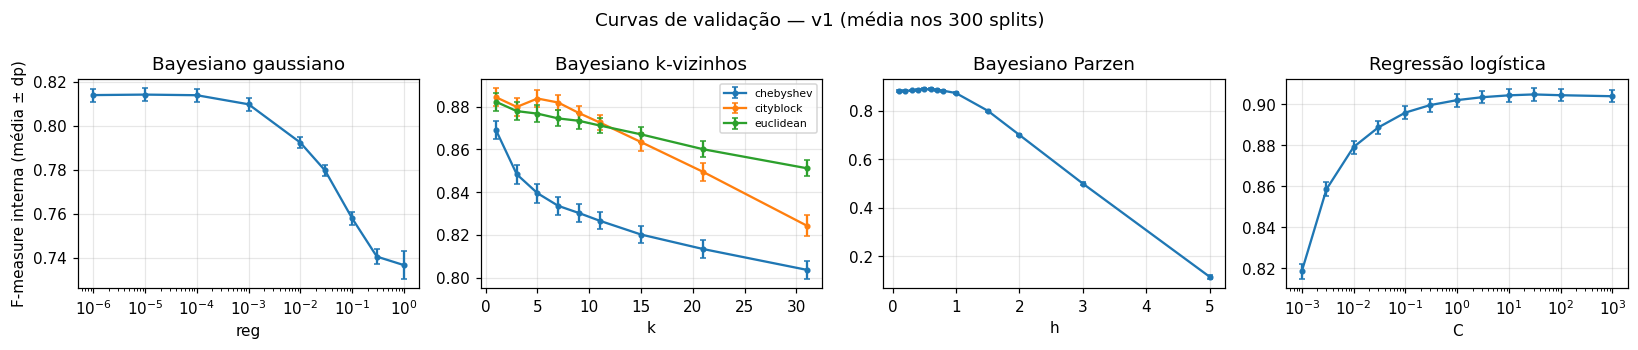

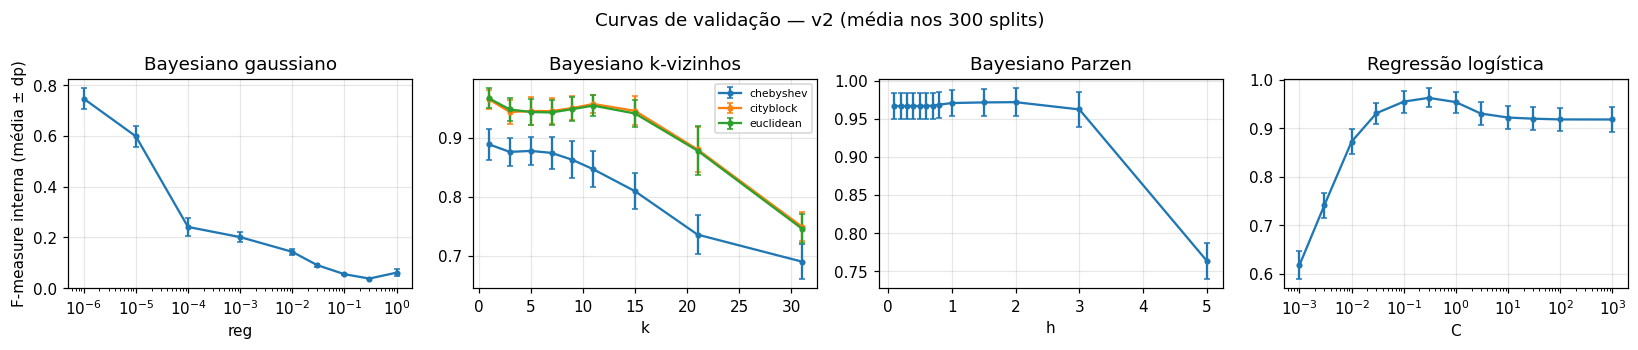

In [28]:
def curvas_de_validacao(versao):
    g = GRADE_CV[versao].copy()
    cfg = g["configuracao"].map(json.loads)
    fig, eixos = plt.subplots(1, 4, figsize=(15, 3.2))
    for eixo, (nome, param) in zip(eixos, [("gaussiano", "reg"), ("knn", "k"), ("parzen", "h"), ("logistica", "C")]):
        sel = g["classificador"] == nome
        dados_c = g[sel].assign(valor=cfg[sel].map(lambda c: c[param]),
                                metrica=cfg[sel].map(lambda c: c.get("metrica", "")))
        for metrica, sub in dados_c.groupby("metrica"):
            m = sub.groupby("valor")["f1_interno"].agg(["mean", "std"])
            eixo.errorbar(m.index, m["mean"], yerr=m["std"], marker="o", ms=3, capsize=2, label=metrica or None)
        if param in ("reg", "C"):
            eixo.set_xscale("log")
        if nome == "knn":
            eixo.legend(fontsize=7)
        eixo.set(title=NOMES[nome], xlabel=param)
    eixos[0].set_ylabel("F-measure interna (média ± dp)")
    fig.suptitle(f"Curvas de validação — {versao} (média nos 300 splits)")
    fig.tight_layout()
    plt.show()


for versao in YS:
    curvas_de_validacao(versao)

**Leitura das curvas de validação.**

- **v1:** o gaussiano é estável de 10⁻⁶ a 10⁻⁴ e piora a partir de 10⁻³. No k-vizinhos, city-block e euclidiana
  com $k$ pequeno são as melhores; Chebyshev é a pior distância (nas duas versões). O Parzen tem um ótimo claro em
  $h \approx 0{,}5$–$0{,}6$ e despenca com $h$ grande. A logística melhora até $C \approx 10$–$100$ e depois fica
  plana.
- **v2:** a F-measure do gaussiano aumenta à medida que `reg` diminui, e o menor valor da grade (10⁻⁶) foi escolhido
  nos 300 splits. O Parzen é praticamente plano
  de $h = 0{,}1$ a $3$, com um leve máximo em $h = 2$; daí a escolha de $h = 2$ ou $3$, em parte pela regra de
  desempate a favor do mais suave. A logística tem um máximo em $C \approx 0{,}3$.

### 3.9 Item (b): estimativa pontual e intervalo de confiança

**Estimativa pontual:** a média das 300 avaliações de cada métrica.

**Intervalo de confiança.** O intervalo $t$ "ingênuo", $\bar m \pm t \cdot s/\sqrt{300}$, supõe 300 avaliações
**independentes**. Mas elas não são independentes: os conjuntos de treino de dois folds compartilham 8/9 dos
exemplos, e cada e-mail é testado 30 vezes. A variância real da média é maior, e o IC ingênuo seria estreito demais.

O projeto usa a **correção de Nadeau & Bengio (2003)**, na forma da CV repetida (Bouckaert & Frank, 2004):

$$\text{EP} = s\sqrt{\frac{1}{300} + \frac{n_{\text{teste}}}{n_{\text{treino}}}} = s\sqrt{\frac{1}{300} + \frac19},
\qquad \text{IC}_{95\%} = \bar m \pm t_{0{,}975;\,299}\cdot \text{EP},$$

cortado no intervalo [0, 1].

In [29]:
def intervalo_confianca(valores, nivel=0.95, corrigido=True):
    valores = np.asarray(valores, float)
    n_aval, media, dp = len(valores), valores.mean(), valores.std(ddof=1)
    ep = dp * np.sqrt(1 / n_aval + 1 / (N_FOLDS - 1)) if corrigido else dp / np.sqrt(n_aval)
    margem = stats.t.ppf((1 + nivel) / 2, df=n_aval - 1) * ep
    return media, max(0.0, media - margem), min(1.0, media + margem)


for versao in YS:
    tabela = pd.DataFrame({NOMES_METRICAS[m]: {NOMES[c]: "{:.4f} [{:.4f}, {:.4f}]".format(
        *intervalo_confianca(RES[versao].loc[RES[versao].classificador == c, m])) for c in ORDEM} for m in METRICAS})
    display(Markdown(f"**{versao}**: média [IC 95%]"), tabela)

# O tamanho da correção, num exemplo
v = RES["v1"].loc[RES["v1"].classificador == "voto", "f_measure"]
_, a, b = intervalo_confianca(v, corrigido=False)
_, c, d = intervalo_confianca(v)
print(f"Exemplo (v1, voto, F-measure): IC ingênuo [{a:.4f}, {b:.4f}] vs corrigido [{c:.4f}, {d:.4f}] "
      f"-> {((d - c) / (b - a)):.1f}× mais largo")

**v1**: média [IC 95%]

,Taxa de erro,Precisão,Cobertura,F-measure
Bayesiano gaussiano,"0.1708 [0.1607, 0.1808]","0.7128 [0.6998, 0.7257]","0.9506 [0.9406, 0.9606]","0.8145 [0.8050, 0.8240]"
Bayesiano k-vizinhos,"0.0860 [0.0773, 0.0946]","0.9132 [0.8968, 0.9296]","0.8649 [0.8456, 0.8842]","0.8879 [0.8764, 0.8995]"
Bayesiano Parzen,"0.0798 [0.0718, 0.0877]","0.9146 [0.9012, 0.9280]","0.8802 [0.8647, 0.8957]","0.8968 [0.8864, 0.9073]"
Regressão logística,"0.0725 [0.0649, 0.0801]","0.9231 [0.9100, 0.9362]","0.8905 [0.8761, 0.9050]","0.9063 [0.8964, 0.9162]"
Voto majoritário,"0.0641 [0.0564, 0.0717]","0.9201 [0.9071, 0.9331]","0.9175 [0.9046, 0.9304]","0.9186 [0.9089, 0.9283]"


**v2**: média [IC 95%]

,Taxa de erro,Precisão,Cobertura,F-measure
Bayesiano gaussiano,"0.0036 [0.0019, 0.0054]","0.7910 [0.6475, 0.9345]","0.7486 [0.5949, 0.9023]","0.7444 [0.6203, 0.8684]"
Bayesiano k-vizinhos,"0.0008 [0.0000, 0.0016]","0.9666 [0.9105, 1.0000]","0.9378 [0.8463, 1.0000]","0.9426 [0.8808, 1.0000]"
Bayesiano Parzen,"0.0003 [0.0000, 0.0009]","0.9748 [0.9260, 1.0000]","0.9875 [0.9348, 1.0000]","0.9772 [0.9324, 1.0000]"
Regressão logística,"0.0006 [0.0000, 0.0013]","0.9464 [0.8795, 1.0000]","0.9906 [0.9417, 1.0000]","0.9632 [0.9126, 1.0000]"
Voto majoritário,"0.0002 [0.0000, 0.0007]","0.9862 [0.9494, 1.0000]","0.9906 [0.9417, 1.0000]","0.9855 [0.9455, 1.0000]"


Exemplo (v1, voto, F-measure): IC ingênuo [0.9170, 0.9203] vs corrigido [0.9089, 0.9283] -> 5.9× mais largo


**Leitura.**

- **v1:** o voto majoritário tem a menor taxa de erro (6,4%) e a maior F-measure (0,919). O gaussiano é o pior em erro
  (17,1%), com um perfil típico: **cobertura altíssima (0,95) e precisão baixa (0,71)**. Ele chama de spam quase tudo
  o que é atípico, porque os dados (muitos zeros, caudas longas) estão longe da normal.
- **v2:** todos erram menos de 0,4%, como esperado de um problema linearmente separável (Seção 2.9). Os IC da
  precisão, da cobertura e da F-measure são **largos**: cada fold de teste tem só 3 ou 4 positivos, e um único erro
  muda a F-measure do fold em ~0,15–0,25.

### 3.10 Item (c): teste de Friedman e pós-teste de Nemenyi

**Friedman.** Em cada uma das $N = 300$ avaliações (os "blocos"), os $k = 5$ classificadores recebem postos de 1
(melhor) a 5: menor taxa de erro, ou maior precisão, cobertura ou F-measure. Empates recebem o posto médio.
$H_0$: todos os classificadores têm o mesmo posto médio $R_j$. Estatística (Demšar, 2006):

$$\chi^2_F = \frac{12N}{k(k+1)}\Big[\sum_j R_j^2 - \frac{k(k+1)^2}{4}\Big] \sim \chi^2_{k-1}.$$

O projeto usa `scipy.stats.friedmanchisquare`, que aplica além disso uma **correção para empates**. Ela importa na
v2, em que muitos blocos têm os 5 classificadores empatados (todos com F = 1).

**Nemenyi.** Se o Friedman rejeita $H_0$, dois classificadores diferem quando a distância entre os seus postos médios
passa da **diferença crítica**

$$CD = q_\alpha\sqrt{\frac{k(k+1)}{6N}}, \qquad q_{0{,}05} = 2{,}728 \ (k = 5),$$

em que $q_\alpha$ é o quantil da amplitude studentizada dividido por $\sqrt2$.

In [30]:
ALFA = 0.05
K_CLF = len(ORDEM)
Q_ALFA = stats.studentized_range.ppf(1 - ALFA, K_CLF, np.inf) / np.sqrt(2)


def matriz_por_bloco(res, metrica, bloco=("repeticao", "fold")):
    # N x 5: valor da métrica de cada classificador em cada bloco.
    return res.pivot_table(index=list(bloco), columns="classificador", values=metrica)[ORDEM]


def postos(matriz, metrica):
    sinal = 1 if metrica == "taxa_erro" else -1           # posto 1 = melhor
    return (sinal * matriz).rank(axis=1, method="average")


def friedman_nemenyi(res, bloco=("repeticao", "fold")):
    linhas, pares, medios_por_metrica = [], [], {}
    for m in METRICAS:
        M = matriz_por_bloco(res, m, bloco)
        N = len(M)
        R = postos(M, m).mean()
        chi2_demsar = 12 * N / (K_CLF * (K_CLF + 1)) * (np.sum(R ** 2) - K_CLF * (K_CLF + 1) ** 2 / 4)
        chi2, p = stats.friedmanchisquare(*[M[c] for c in ORDEM])          # com correção para empates
        cd = Q_ALFA * np.sqrt(K_CLF * (K_CLF + 1) / (6 * N))
        medios_por_metrica[m] = (R, cd)
        linhas.append({"métrica": NOMES_METRICAS[m], "N": N, "χ² (fórmula)": chi2_demsar, "χ² (com empates)": chi2,
                       "p-valor": p, "rejeita H0": p < ALFA, "CD": cd,
                       "postos médios": ", ".join(f"{CURTOS[c]} {v:.2f}" for c, v in R.sort_values().items())})
        for i, a in enumerate(ORDEM):
            for b_ in ORDEM[i + 1:]:
                pares.append({"métrica": NOMES_METRICAS[m], "par": f"{CURTOS[a]} × {CURTOS[b_]}",
                              "|ΔR|": abs(R[a] - R[b_]), "difere": bool(p < ALFA and abs(R[a] - R[b_]) > cd)})
    return pd.DataFrame(linhas), pd.DataFrame(pares), medios_por_metrica


FN = {v: friedman_nemenyi(RES[v]) for v in YS}
for versao, (tab, pares, _) in FN.items():
    t = tab.set_index("métrica").round({"χ² (fórmula)": 1, "χ² (com empates)": 1, "CD": 3})
    t["p-valor"] = t["p-valor"].map("{:.1e}".format)
    display(Markdown(f"**{versao}**: Friedman"), t)
    iguais = pares[~pares.difere].groupby("métrica", sort=False)["par"].agg("; ".join)
    display(Markdown(f"**{versao}**: pares **sem** diferença significativa (Nemenyi)"),
            iguais.reindex([NOMES_METRICAS[m] for m in METRICAS]).fillna("nenhum (todos diferem)").to_frame())

**v1**: Friedman

,N,χ² (fórmula),χ² (com empates),p-valor,rejeita H0,CD,postos médios
métrica,,,,,,,
Taxa de erro,300,942.5,957.2,6.7e-206,True,0.352,"Voto 1.26, Logística 2.25, Parzen 2.97, kNN 3.52, Gaussiano 5.00"
Precisão,300,636.3,636.8,1.7e-136,True,0.352,"Logística 2.17, Voto 2.29, Parzen 2.71, kNN 2.83, Gaussiano 5.00"
Cobertura,300,971.8,984.1,9.7e-212,True,0.352,"Gaussiano 1.04, Voto 2.06, Logística 3.44, Parzen 3.94, kNN 4.51"
F-measure,300,975.0,975.5,7.4e-210,True,0.352,"Voto 1.19, Logística 2.28, Parzen 2.96, kNN 3.57, Gaussiano 5.00"


**v1**: pares **sem** diferença significativa (Nemenyi)

,par
métrica,
Taxa de erro,nenhum (todos diferem)
Precisão,kNN × Parzen; Logística × Voto
Cobertura,nenhum (todos diferem)
F-measure,nenhum (todos diferem)


**v2**: Friedman

,N,χ² (fórmula),χ² (com empates),p-valor,rejeita H0,CD,postos médios
métrica,,,,,,,
Taxa de erro,300,355.8,617.8,2.2e-132,True,0.352,"Voto 2.35, Parzen 2.48, Logística 2.74, kNN 2.94, Gaussiano 4.49"
Precisão,300,149.4,349.5,2.2e-74,True,0.352,"Voto 2.59, Parzen 2.69, kNN 2.78, Logística 2.98, Gaussiano 3.96"
Cobertura,300,215.4,567.4,1.8e-121,True,0.352,"Logística 2.60, Voto 2.60, Parzen 2.62, kNN 3.02, Gaussiano 4.16"
F-measure,300,378.9,641.6,1.6e-137,True,0.352,"Voto 2.35, Parzen 2.46, Logística 2.71, kNN 2.96, Gaussiano 4.53"


**v2**: pares **sem** diferença significativa (Nemenyi)

,par
métrica,
Taxa de erro,kNN × Logística; Parzen × Logística; Parzen × Voto
Precisão,kNN × Parzen; kNN × Logística; kNN × Voto; Parzen × Logística; Parzen × Voto
Cobertura,Parzen × Logística; Parzen × Voto; Logística × Voto
F-measure,kNN × Logística; Parzen × Logística; Parzen × Voto


**Diagrama de diferença crítica.** No gráfico abaixo, cada classificador ocupa uma linha, com o ponto no seu posto
médio e uma barra de comprimento CD centrada nele (±CD/2). **Duas barras que não se sobrepõem indicam postos médios
significativamente diferentes** pelo Nemenyi. É uma forma equivalente ao diagrama clássico de Demšar, mas sem
rótulos sobrepostos.

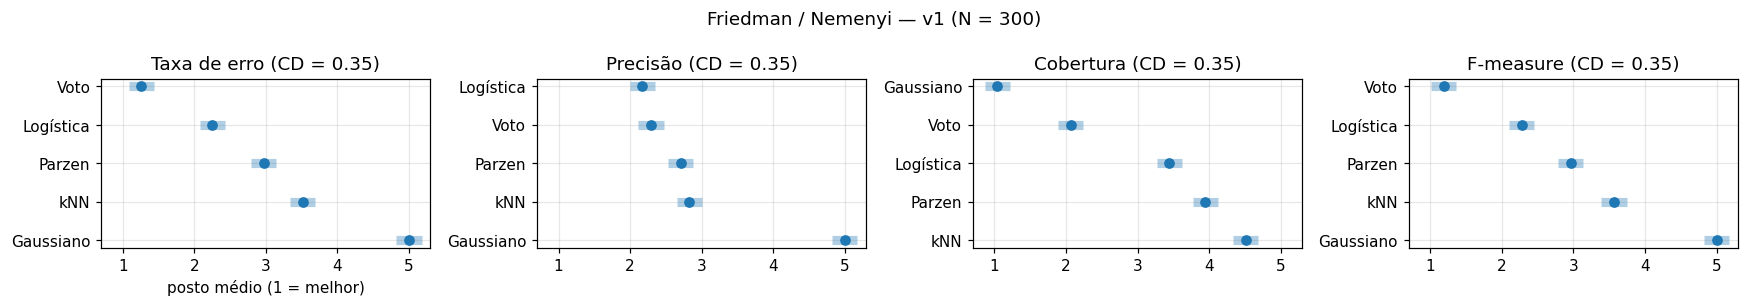

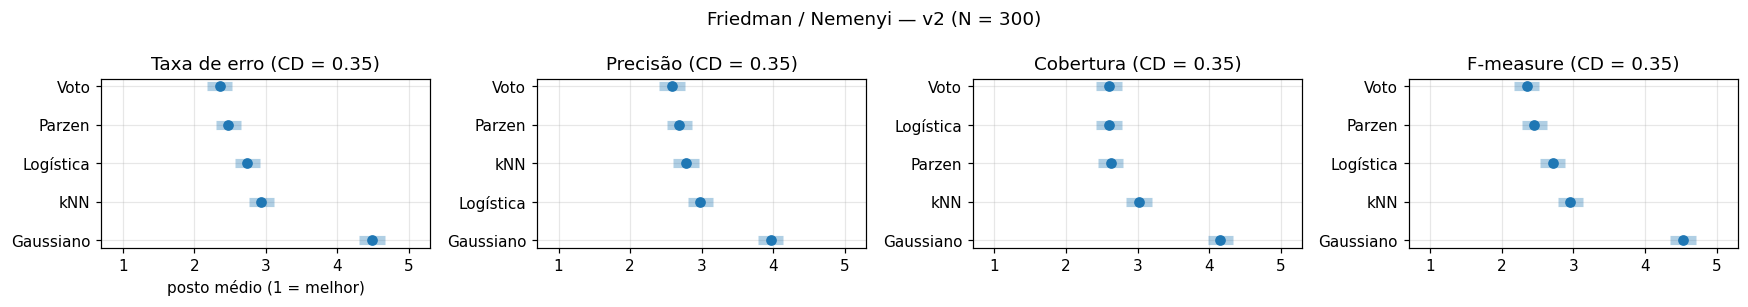

In [31]:
def diagrama_cd(medios_por_metrica, titulo):
    fig, eixos = plt.subplots(1, 4, figsize=(16, 2.8), sharex=True)
    for eixo, m in zip(eixos, METRICAS):
        R, cd = medios_por_metrica[m]
        R = R.sort_values(ascending=False)                      # melhor em cima
        ypos = np.arange(len(R))
        eixo.hlines(ypos, R - cd / 2, R + cd / 2, lw=6, color="tab:blue", alpha=0.35)
        eixo.plot(R, ypos, "o", color="tab:blue")
        eixo.set_yticks(ypos, [CURTOS[c] for c in R.index])
        eixo.set(title=f"{NOMES_METRICAS[m]} (CD = {cd:.2f})", xlim=(0.7, 5.3))
    eixos[0].set_xlabel("posto médio (1 = melhor)")
    fig.suptitle(titulo)
    fig.tight_layout()
    plt.show()


for versao, (_, _, medios) in FN.items():
    diagrama_cd(medios, f"Friedman / Nemenyi — {versao} (N = 300)")

**Leitura.**

- **v1:** o Friedman rejeita $H_0$ nas 4 métricas. Em taxa de erro e F-measure, a ordem é voto < logística < Parzen <
  k-vizinhos < gaussiano, e **todos os pares diferem**. Em precisão, k-vizinhos × Parzen e logística × voto não
  diferem. Em cobertura, o gaussiano é o primeiro, coerente com o perfil "chama tudo de spam" visto no item (b).
- **v2:** o Friedman também rejeita $H_0$, mas as diferenças entre k-vizinhos, Parzen, logística e voto são pequenas e
  vários pares não são significativos. O gaussiano é o pior em todas as métricas.

### 3.11 Item (d): curvas de aprendizagem

**Como foi feito.**

- Proporções de treino $p$ = 5%, 10%, …, 95% (teste = $1 - p$), com divisão **estratificada** da base inteira.
- **5 sorteios** por proporção, para ver a variabilidade (média ± 1 desvio-padrão no gráfico).
- Os 5 classificadores são treinados no treino, e as **4 métricas** são calculadas **no próprio treino e no teste**.
  O gráfico mostra a F-measure, como pede o enunciado; as outras métricas estão na tabela.
- **Hiper-parâmetros fixos** em cada proporção: a configuração mais escolhida no item (a). Escolher por CV em cada
  tamanho não é possível nos menores: com 5% de treino, a classe positiva da v2 tem só 2 exemplos, e não dá para
  formar 5 folds estratificados.

**Como ler.** A distância entre a curva de treino e a de teste indica **variância** (sobreajuste). Se as duas curvas
convergem num valor baixo, o problema é **viés** (modelo inadequado) e mais dados não ajudam.

In [32]:
PROPORCOES = np.round(np.arange(0.05, 0.96, 0.05), 2)
N_SORTEIOS = 5


def hiperparametros_mais_escolhidos(res):
    return {nome: json.loads(res.loc[res.classificador == nome, "hiperparametros"].mode()[0]) for nome in CLASSIFICADORES}


def avaliar_proporcao(X, y, proporcao, sorteio, configs):
    divisao = StratifiedShuffleSplit(n_splits=1, train_size=proporcao, random_state=SEMENTE + sorteio)
    idx_tr, idx_te = next(divisao.split(X, y))
    conjuntos = {"treino": idx_tr, "teste": idx_te}
    linhas, preds, probas = [], {c: [] for c in conjuntos}, {c: [] for c in conjuntos}
    for nome, cls in CLASSIFICADORES.items():
        modelo = cls(**configs[nome]).fit(X[idx_tr], y[idx_tr])
        for conjunto, idx in conjuntos.items():
            preds[conjunto].append(modelo.predict(X[idx]))
            probas[conjunto].append(modelo.predict_proba(X[idx]))
            linhas.append({"classificador": nome, "conjunto": conjunto, **calcular_metricas(y[idx], preds[conjunto][-1])})
    for conjunto, idx in conjuntos.items():
        voto = voto_majoritario(preds[conjunto], probas[conjunto], modelo.classes_)
        linhas.append({"classificador": "voto", "conjunto": conjunto, **calcular_metricas(y[idx], voto)})
    for linha in linhas:
        linha.update(proporcao_treino=proporcao, repeticao=sorteio + 1)
    return linhas


CURVA = {}
for versao, y in YS.items():
    configs = hiperparametros_mais_escolhidos(RES[versao])
    print(f"{versao}: hiper-parâmetros fixos = {configs}")
    oficial = pd.read_csv(Q2_OUT / f"curva_{versao}.csv")
    if RODAR_CURVAS:
        saidas = Parallel(n_jobs=N_JOBS)(delayed(avaliar_proporcao)(X, y, p, r, configs)
                                         for p in PROPORCOES for r in range(N_SORTEIOS))
        CURVA[versao] = pd.DataFrame([l for ls in saidas for l in ls])
        chave = ["classificador", "conjunto", "proporcao_treino", "repeticao"]
        junta = CURVA[versao].merge(oficial, on=chave, suffixes=("", "_of"))
        dif = max(np.abs(junta[m] - junta[m + "_of"]).max() for m in METRICAS)
        print(f"     {len(junta)} linhas comparadas com curva_{versao}.csv; maior diferença = {dif:.1e}")
    else:
        CURVA[versao] = oficial

v1: hiper-parâmetros fixos = {'gaussiano': {'reg': 1e-05}, 'knn': {'metrica': 'cityblock', 'k': 1}, 'parzen': {'h': 0.5}, 'logistica': {'C': 30.0}}


     950 linhas comparadas com curva_v1.csv; maior diferença = 1.1e-16
v2: hiper-parâmetros fixos = {'gaussiano': {'reg': 1e-06}, 'knn': {'metrica': 'euclidean', 'k': 1}, 'parzen': {'h': 2.0}, 'logistica': {'C': 0.1}}


     950 linhas comparadas com curva_v2.csv; maior diferença = 1.1e-16


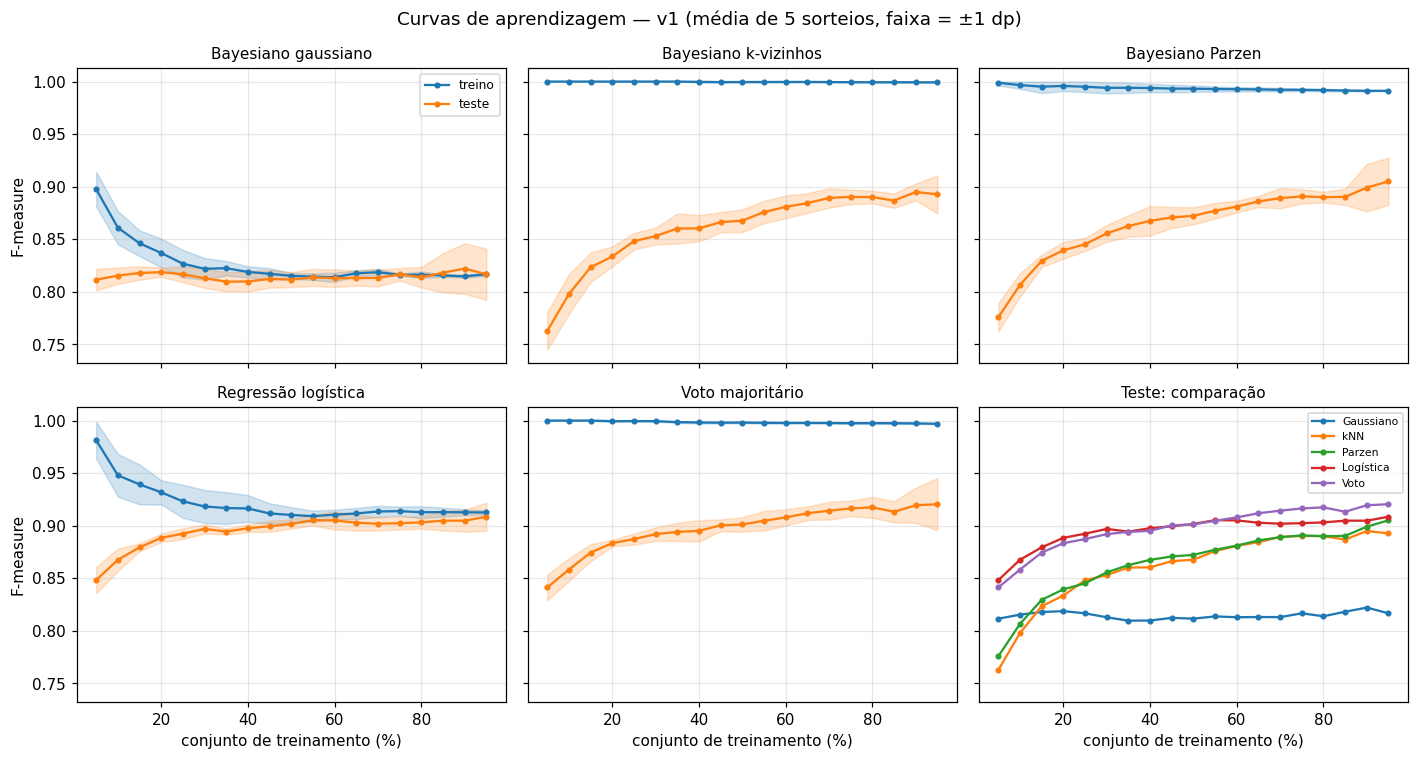

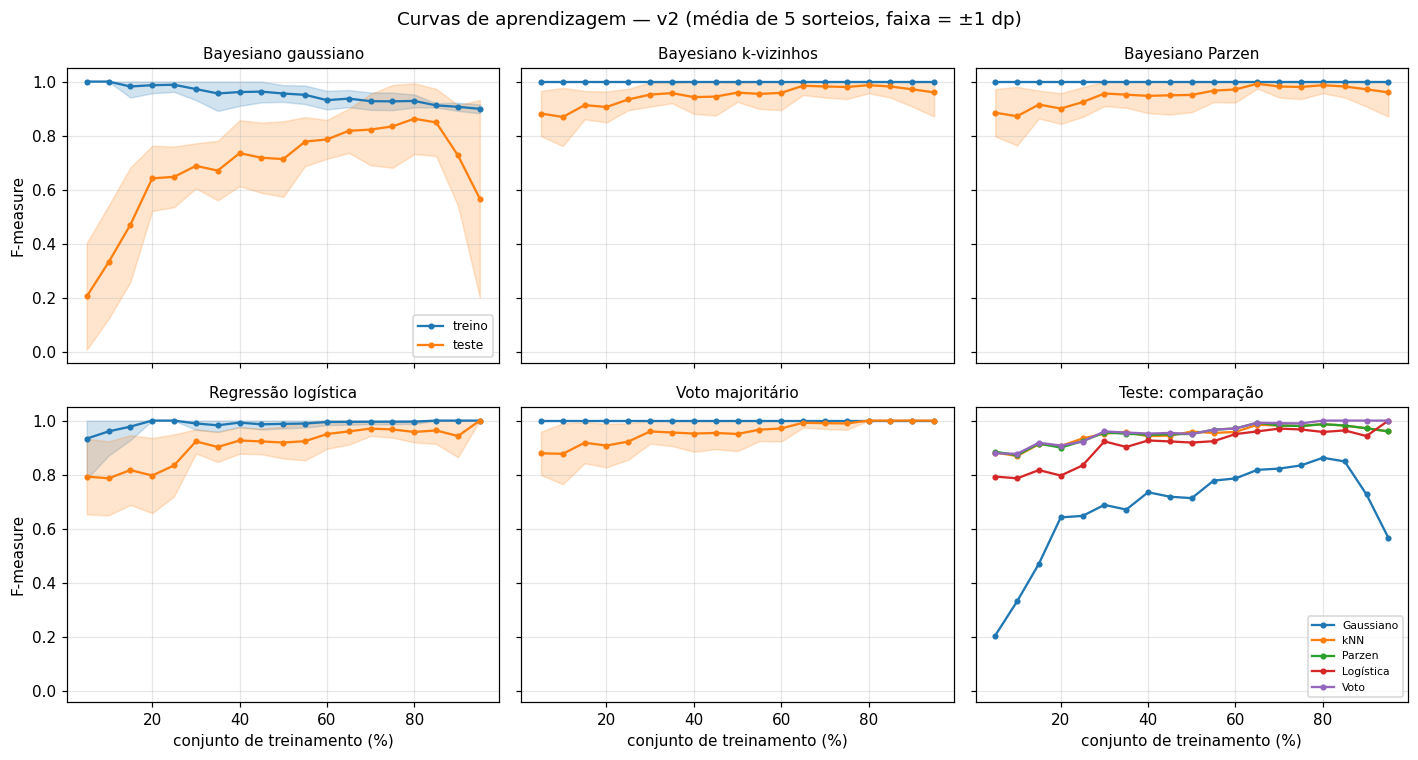

In [33]:
def grafico_curvas(curva, versao):
    resumo = curva.groupby(["classificador", "conjunto", "proporcao_treino"])["f_measure"].agg(["mean", "std"])
    fig, eixos = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
    for eixo, nome in zip(eixos.flat, ORDEM):
        for conjunto, cor in (("treino", "tab:blue"), ("teste", "tab:orange")):
            r = resumo.loc[(nome, conjunto)]
            eixo.plot(r.index * 100, r["mean"], "o-", ms=3, color=cor, label=conjunto)
            eixo.fill_between(r.index * 100, r["mean"] - r["std"], (r["mean"] + r["std"]).clip(upper=1),
                              color=cor, alpha=0.2)
        eixo.set_title(NOMES[nome], fontsize=10)
    eixo = eixos.flat[-1]
    for nome in ORDEM:
        r = resumo.loc[(nome, "teste")]
        eixo.plot(r.index * 100, r["mean"], "o-", ms=3, label=CURTOS[nome])
    eixo.set_title("Teste: comparação", fontsize=10)
    eixo.legend(fontsize=7)
    eixos.flat[0].legend(fontsize=8)
    for e in eixos[-1]:
        e.set_xlabel("conjunto de treinamento (%)")
    for e in eixos[:, 0]:
        e.set_ylabel("F-measure")
    fig.suptitle(f"Curvas de aprendizagem — {versao} (média de {N_SORTEIOS} sorteios, faixa = ±1 dp)")
    fig.tight_layout()
    plt.show()


for versao in YS:
    grafico_curvas(CURVA[versao], versao)

In [34]:
# As 4 métricas (média dos 5 sorteios) em algumas proporções de treino
for versao in YS:
    sel = CURVA[versao][CURVA[versao].proporcao_treino.isin([0.05, 0.25, 0.5, 0.75, 0.95])]
    tab = sel.pivot_table(index=["classificador", "conjunto"], columns="proporcao_treino", values=list(METRICAS))
    tab = (tab[list(METRICAS)].reindex(ORDEM, level=0)
           .rename(index=NOMES, level=0).rename(columns=NOMES_METRICAS, level=0))
    display(Markdown(f"**{versao}**: métricas (média dos 5 sorteios) no treino e no teste, por proporção de treino"),
            tab.round(3))

**v1**: métricas (média dos 5 sorteios) no treino e no teste, por proporção de treino

Taxa de erro                              \
proporcao_treino                      0.05   0.25   0.50   0.75   0.95   
classificador        conjunto                                            
Bayesiano gaussiano  teste           0.161  0.166  0.173  0.168  0.169   
                     treino          0.090  0.157  0.170  0.169  0.169   
Bayesiano k-vizinhos teste           0.173  0.116  0.103  0.085  0.082   
                     treino          0.000  0.000  0.000  0.000  0.001   
Bayesiano Parzen     teste           0.168  0.119  0.099  0.084  0.074   
                     treino          0.001  0.004  0.005  0.006  0.007   
Regressão logística  teste           0.120  0.084  0.077  0.076  0.072   
                     treino          0.015  0.059  0.069  0.067  0.068   
Voto majoritário     teste           0.121  0.088  0.078  0.066  0.063   
                     treino          0.000  0.000  0.001  0.002  0.002   

                              Precisão                             Cobertura  \
proporcao_treino                  0.05   0.25   0.50   0.75   0.95      0.05   
classificador        conjunto                                                  
Bayesiano gaussiano  teste       0.755  0.722  0.711  0.717  0.714     0.878   
                     treino      0.815  0.731  0.712  0.714  0.714     1.000   
Bayesiano k-vizinhos teste       0.834  0.880  0.882  0.908  0.920     0.705   
                     treino      1.000  1.000  1.000  1.000  1.000     1.000   
Bayesiano Parzen     teste       0.818  0.869  0.890  0.911  0.910     0.740   
                     treino      1.000  1.000  1.000  1.000  1.000     0.998   
Regressão logística  teste       0.843  0.901  0.912  0.917  0.912     0.854   
                     treino      0.985  0.939  0.927  0.929  0.930     0.978   
Voto majoritário     teste       0.875  0.898  0.904  0.923  0.914     0.811   
                     treino      1.000  1.000  0.998  0.998  0.997     1.000   

                                                          F-measure         \
proporcao_treino                0.25   0.50   0.75   0.95      0.05   0.25   
classificador        conjunto                                                
Bayesiano gaussiano  teste     0.940  0.946  0.949  0.954     0.812  0.817   
                     treino    0.952  0.954  0.953  0.955     0.898  0.827   
Bayesiano k-vizinhos teste     0.819  0.854  0.874  0.868     0.763  0.848   
                     treino    1.000  0.999  0.999  0.998     1.000  1.000   
Bayesiano Parzen     teste     0.823  0.855  0.872  0.901     0.776  0.845   
                     treino    0.990  0.987  0.985  0.983     0.999  0.995   
Regressão logística  teste     0.884  0.892  0.888  0.905     0.848  0.892   
                     treino    0.908  0.894  0.899  0.896     0.981  0.923   
Voto majoritário     teste     0.877  0.899  0.911  0.927     0.841  0.887   
                     treino    1.000  0.998  0.997  0.997     1.000  1.000   

                                                    
proporcao_treino                0.50   0.75   0.95  
classificador        conjunto                       
Bayesiano gaussiano  teste     0.812  0.817  0.817  
                     treino    0.815  0.816  0.817  
Bayesiano k-vizinhos teste     0.868  0.890  0.893  
                     treino    1.000  0.999  0.999  
Bayesiano Parzen     teste     0.872  0.891  0.905  
                     treino    0.993  0.992  0.991  
Regressão logística  teste     0.902  0.902  0.909  
                     treino    0.910  0.914  0.913  
Voto majoritário     teste     0.901  0.916  0.920  
                     treino    0.998  0.997  0.997

**v2**: métricas (média dos 5 sorteios) no treino e no teste, por proporção de treino

Taxa de erro                              \
proporcao_treino                      0.05   0.25   0.50   0.75   0.95   
classificador        conjunto                                            
Bayesiano gaussiano  teste           0.006  0.004  0.004  0.002  0.005   
                     treino          0.000  0.000  0.001  0.001  0.002   
Bayesiano k-vizinhos teste           0.002  0.001  0.001  0.000  0.001   
                     treino          0.000  0.000  0.000  0.000  0.000   
Bayesiano Parzen     teste           0.002  0.001  0.001  0.000  0.001   
                     treino          0.000  0.000  0.000  0.000  0.000   
Regressão logística  teste           0.002  0.002  0.001  0.001  0.000   
                     treino          0.001  0.000  0.000  0.000  0.000   
Voto majoritário     teste           0.002  0.001  0.001  0.000  0.000   
                     treino          0.000  0.000  0.000  0.000  0.000   

                              Precisão                             Cobertura  \
proporcao_treino                  0.05   0.25   0.50   0.75   0.95      0.05   
classificador        conjunto                                                  
Bayesiano gaussiano  teste       0.600  0.945  0.841  0.920  0.700     0.125   
                     treino      1.000  0.978  0.917  0.865  0.817     1.000   
Bayesiano k-vizinhos teste       0.955  0.985  0.944  0.964  0.933     0.838   
                     treino      1.000  1.000  1.000  1.000  1.000     1.000   
Bayesiano Parzen     teste       0.961  0.985  0.952  0.964  0.933     0.838   
                     treino      1.000  1.000  1.000  1.000  1.000     1.000   
Regressão logística  teste       1.000  0.969  0.943  0.960  1.000     0.675   
                     treino      1.000  1.000  1.000  1.000  1.000     0.900   
Voto majoritário     teste       0.975  0.993  0.952  0.980  1.000     0.812   
                     treino      1.000  1.000  1.000  1.000  1.000     1.000   

                                                        F-measure         \
proporcao_treino                0.25   0.50   0.75 0.95      0.05   0.25   
classificador        conjunto                                              
Bayesiano gaussiano  teste     0.500  0.624  0.778  0.5     0.205  0.647   
                     treino    1.000  1.000  1.000  1.0     1.000  0.988   
Bayesiano k-vizinhos teste     0.892  0.976  1.000  1.0     0.882  0.934   
                     treino    1.000  1.000  1.000  1.0     1.000  1.000   
Bayesiano Parzen     teste     0.877  0.953  1.000  1.0     0.885  0.924   
                     treino    1.000  1.000  1.000  1.0     1.000  1.000   
Regressão logística  teste     0.754  0.906  0.978  1.0     0.793  0.834   
                     treino    1.000  0.976  0.992  1.0     0.933  1.000   
Voto majoritário     teste     0.869  0.953  1.000  1.0     0.879  0.923   
                     treino    1.000  1.000  1.000  1.0     1.000  1.000   

                                                    
proporcao_treino                0.50   0.75   0.95  
classificador        conjunto                       
Bayesiano gaussiano  teste     0.713  0.834  0.567  
                     treino    0.956  0.927  0.899  
Bayesiano k-vizinhos teste     0.959  0.980  0.960  
                     treino    1.000  1.000  1.000  
Bayesiano Parzen     teste     0.951  0.980  0.960  
                     treino    1.000  1.000  1.000  
Regressão logística  teste     0.919  0.967  1.000  
                     treino    0.988  0.996  1.000  
Voto majoritário     teste     0.951  0.989  1.000  
                     treino    1.000  1.000  1.000

**Comentário (o enunciado pede).**

*Versão 1*

- **Gaussiano:** as curvas de treino e de teste **convergem para ~0,81**. É **viés**: o modelo normal multivariado é
  inadequado para estes dados, e mais dados não ajudam. Com pouco treino, a F de treino é maior que a de teste,
  porque a covariância se ajusta ao próprio treino.
- **k-vizinhos e Parzen:** a F-measure de **treino é ~1** (com $k = 1$ e $h$ pequeno, cada exemplo de treino é o seu
  próprio vizinho ou pico de densidade), e a de **teste sobe** com o tamanho do treino. É **variância alta**, que
  diminui com mais dados; as curvas ainda não se estabilizaram em 95%.
- **Logística:** a diferença entre treino e teste **fecha a partir de ~50%**, e o teste estabiliza em ~0,90.
- **Voto:** é o melhor no teste a partir de ~45% de treino e herda a F de treino ~1 do k-vizinhos e do Parzen.

*Versão 2*

- As curvas de teste são **ruidosas**: com 95% de treino, o teste tem só 2 positivos.
- O **gaussiano** precisa de muitos dados (estimar uma covariância 57 × 57 com poucos positivos); a sua F de teste
  sobe de ~0,2 para ~0,85, mas oscila muito.
- Os demais ficam entre ~0,8 e 1 desde 5% de treino, coerente com um problema separável.

---
## 4. Arquivos do repositório

| O quê | Arquivo |
|---|---|
| Dados | `double-kmeans-spambase/data/spambase.data` (e `spambase.names`) |
| Q1: implementação oficial (R) | `double-kmeans-spambase/double_kmeans_spambase.R` |
| Q1: saídas (tabela K,H; G; confusão; ARI; gráficos) | `double-kmeans-spambase/output/` (resumo visual em `report.html`) |
| Q1 → Q2: rótulos da v2 | `double-kmeans-spambase/output/cl_star.csv` (refeito sem R por `questao-02/reconstroi_cl_star.py`) |
| Q2: dados, splits, métricas, IC | `questao-02/comum.py` |
| Q2: os 5 classificadores e a seleção de hiper-parâmetros | `questao-02/classificadores.py` |
| Q2 (a): CV aninhada 30 × 10 | `questao-02/executar_cv.py` → `output/resultados_cv_*.csv`, `output/grade_cv_*.csv` |
| Q2 (b), (c): IC, Friedman, Nemenyi | `questao-02/analisar.py` → `output/ic_*`, `friedman_*`, `nemenyi_*`, `cd_*.png`, `resultados.md` |
| Q2 (d): curvas | `questao-02/curva_aprendizagem.py` → `output/curva_*` |
| Q2: splits sorteados | `questao-02/splits/folds_*.csv` |
| Experimentos preliminares (não são os finais) | `classificadores-modelo-original/` |